# 1-board: bridge-states

Check the burst inductance method on a load with no moving parts, read what the shunt and the terminal taps show in each bridge state when the load carries a real inductive current, time the bridge's edges and the shunt amplifier in fast decay, and measure the dummy's DC resistance.

## Purpose

The burst method reads a winding's inductance from duty steps with the ADC free running on the shunt and both terminal taps, and stage 2 reads the motor's winding with it. It reads the inductance two ways. The period fit takes the current at the middle of each drive window and the volts each period applied, and fits $R$ and $L$ over the rise. The ripple reading takes the slope of the current inside one window. A brushed motor with an iron rotor can make the two disagree on its own, since eddy currents in the iron make an inductance that looks smaller to a fast change of current than to a slow one. A bias in either reading would make the same kind of gap on any load, so the method's own share has to be known before a gap on a motor can be read.

So the method is run here, unchanged, on a load whose inductance should not depend on the time scale it is read over. Two power inductors on powdered iron toroids, well under their rated current, are the closest thing to that on the bench. Whatever gap the ripple and the fit leave on them belongs to the method. The same wirings test three more things. The bare resistor alone should give next to no inductance, the two inductors in series should add, and the fitted $R$ should match the DC resistance of the same wiring.

The second question is what the shunt and the taps read through one PWM period when the load carries current between windows. The stage 1 resistor loads carry none there in either decay mode. Under slow decay the bridge shorts the load through its two low-side switches between windows, and under fast decay it opens all four and the current returns to the rail through the body diodes. An inductor keeps its current flowing through both, so this is the first load on which the shunt and the taps see those states with a current in them.

The third is the dummy's own DC resistance, each wiring's and so each inductor's copper by difference, which the fits are compared with.

The fourth is where the bridge's edges sit in fast decay, and how the shunt amplifier follows them. Sample-timing timed the edges in slow decay, where the bridge brakes the load through its two low-side switches between windows. There a window's ON edge turns the driven leg's low side off and waits out the driver's dead time, the pause that keeps a leg's two switches from ever being on together, before its high side turns on. In fast decay all four switches are off between windows, so the ON edge turns the diagonal pair on with no dead time before it, and it should come earlier. A reading that places a fast-decay window against its edges, such as a line through the window carried back to the ON edge, needs those edges, and they are board constants. They are fitted here through a tick-level model of the bridge on the resistor and on one inductor, with the amplifier's lag and gain beside them.

## Procedure

The RL dummy is the bare 5 ohm power resistor from stage 0 in series with up to two Bourns 2300LL-102-H-RC power inductors, 1 mH and 0.137 ohm nominal each, wound on powdered iron toroids. Their inductance falls to 380 uH at 3.5 A, and the most any capture here puts through them is about 0.9 A. Inductor A has orange leads and inductor B brown leads. The parts are joined with Dupont pigtails, MOT_A to the resistor to the inductors to MOT_B. There are four wirings, and each change adds or removes one part.

- `r`, the resistor alone, the control.
- `ra`, the resistor and A.
- `rab`, the resistor, A and B in series.
- `rb`, the resistor and B.

`capture.py` runs the same parts on every wiring.

- DC laps at 100 % on a 3.7 V and a 4.2 V rail, the stage 1 laps, both directions, three seconds each. At 100 % the bridge stops switching and the inductance drops out, so the laps give the wiring's DC resistance.
- On a 5.0 V rail, `osc-lab burst` at 25 and 40 %, both signs, five repeats each, the shunt and both taps interleaved, once in slow decay and once in fast. The twenty bursts of one decay run in four sets of five, 25 % forward, 25 % reverse, 40 % forward and 40 % reverse, with 150 ms of rest between bursts.
- On the same rail, `osc-lab sweep` at 25 and 40 % with the 100 % rung as the control, both directions, 150 ms a rung, once in each decay. Its row carries the trough shunt sample beside the crest samples.

One inductor with the resistor is about 1 mH over 5.2 ohm, a time constant of about 0.19 ms or four PWM periods, and both in series about 0.37 ms or seven periods. A burst runs about nine periods past the step, so a slow-decay burst ends near 90 % of its settled current on one inductor and near 70 % on both, and both curves bend inside the capture.

1. The board on the DPS, the adapter on its bus at 3 Mbps, the board on the experiment image.
2. The resistor alone between MOT_A and MOT_B.
3. `uv run python stages/1-board/bridge-states/capture.py`. It runs the laps, the bursts and the sweeps on the wiring, steps the rail back to 3.7 V, and asks for the next wiring with the bridge off, four times in all.

The resistor takes 3.5 W on a 4.2 V lap and 4.9 W on the 100 % rung at 5 V, under its 12 W.

## Data

- `capture-1/<wiring>/laps/K/` and `levels.csv`, the two DC laps of each wiring, a `sweep.csv` and a `meta.json` per lap as in the other stage 1 lap experiments.
- `capture-1/<wiring>/bursts-slow/burst-K.csv` and `bursts-fast/burst-K.csv`, one file per burst, twenty per decay. `k` is the sample index, `code` the raw ADC sample, and the meta fields repeat on the first row. `step_q15` is the step's duty and sign, `step_index` the sample at which the step was applied, `start_cnt` and `start_dir` the PWM counter at the first sample, `pwm_arr` the counter's crest, `frame_len` the frame, `vbus_raw` the rail read before the arm and `vmotor_bias` the taps' bias reading. `meta.json` beside them carries the board's sense block and the decay the tool ran.
- `capture-1/<wiring>/sweep-slow/` and `sweep-fast/`, one `sweep.csv` and `meta.json` each. `current_raw` is the crest sample, `current_trough` the trough sample, `vmotor_a` and `vmotor_b` the taps and `vbus_raw` the rail tap.
- `capture-1/marks.csv`, the host time at which each wiring went on and each part began.

A burst's timing is read the way the inductance notebook reads it.

- A frame is the shunt, tap A, the shunt, tap B, one conversion every 26 ADC clocks at 24 MHz, 1.083 us. The shunt is read 23 times per 50 us PWM period and each tap 11 to 12 times.
- A burst holds 960 samples, 1.04 ms, with the step near the middle, so the first half is the amplifier's zero and the second half about ten PWM periods after the step.
- The phase of each sample comes from the counter at the first sample and the fixed sample spacing, as `oscnb.bursts.phase` computes it, with the aperture of 13.5 ADC clocks added so a sample is placed where its aperture closed.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from oscnb import boards, bursts as bu, laps, results, tel

BLUE, ORANGE, AQUA, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781"   # the house colors and the third categorical slot
BOARD = boards.BOARDS[boards.DEFAULT]                                   # the board, with the parts' nominal values
CAPTURE = (Path("../../../telemetry") / BOARD.key / "bridge-states" / "capture-1").resolve()
# the four wirings in capture order, each change adding or removing one part
WIRINGS = {"r": "the resistor alone", "ra": "the resistor and A", "rab": "the resistor, A and B", "rb": "the resistor and B"}
COLOR = {"r": MUTED, "ra": BLUE, "rab": AQUA, "rb": ORANGE}            # one color per wiring, fixed through the notebook
INDUCTORS = ("ra", "rab", "rb")                                         # the wirings with an inductor in them
# the inductors' nominal values, Bourns 2300LL-102-H-RC, from the part's datasheet: 1 mH and 0.137 ohm of copper each
L_NOM_MH, DCR_NOM_OHM = 1.0, 0.137
L_NOM = {"r": 0.0, "ra": L_NOM_MH, "rab": 2 * L_NOM_MH, "rb": L_NOM_MH}   # the nominal inductance each wiring holds
ARR = BOARD.pwm_arr                                                     # ticks from the trough to the crest
PERIOD = 2 * ARR                                                        # ticks per PWM period, trough to trough
US = bu.STEP_TICKS / bu.TICKS_PER_US                                    # microseconds from one sample to the next
PERIOD_US = PERIOD / bu.TICKS_PER_US                                    # microseconds per PWM period
T_S = PERIOD_US * 1e-6                                                  # the same period in seconds, for the fit
print(BOARD.key, "from", results.rel(CAPTURE))
print(f"a sample every {US:.3f} us, {PERIOD / bu.STEP_TICKS:.1f} samples per {PERIOD_US:.0f} us period")

# the stage 1 conversions the counts go through, measured, from the result files
CS = results.read("1-board", "current-scale", pair=BOARD.key)          # counts per amp on the meter, and the in-drive offset
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)         # terminal counts per volt on the meter, and its offset
ST = results.read("1-board", "sample-timing", pair=BOARD.key)          # the bridge's edge lags and the shunt's settle
PR = results.read("0-instruments", "power-resistors")                  # the bare resistor's cold value, its leads excluded
COUNTS_PER_A, DRIVE_OFF = CS["counts_per_a"]["value"], CS["drive_offset_counts"]["value"]
COUNTS_PER_V, TERM_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]
# 5.0 V sits between the two rails sample-timing graded, so the lags are the mean of the two, as in the inductance notebook
ON_LAG = np.mean([ST["on_edge_lag_7v4"]["value"], ST["on_edge_lag_3v7"]["value"]])            # the shunt's half crossing after the commanded start
TAP_ON_LAG = np.mean([ST["tap_on_edge_lag_7v4"]["value"], ST["tap_on_edge_lag_3v7"]["value"]])   # the bridge's own ON edge, from the tap
OFF_LAG = np.mean([ST["off_edge_lag_7v4"]["value"], ST["off_edge_lag_3v7"]["value"]])          # the bridge's OFF edge after the commanded end
SETTLE = np.mean([ST["shunt_settle_7v4"]["value"], ST["shunt_settle_3v7"]["value"]])           # the shunt settled, ticks after the commanded start
print(f"current, counts over the zero = {DRIVE_OFF:+.1f} + {COUNTS_PER_A:.1f} x amps. Terminals, tap difference = {TERM_OFF:+.1f} + {COUNTS_PER_V:.2f} x volts")
print(f"bridge ON edge {TAP_ON_LAG:.0f} ticks after the commanded start, OFF edge {OFF_LAG:.0f} after the commanded end, shunt settled {SETTLE:.0f} after the start")
print(f"bare resistor, stage 0, {PR['bare']['r_cold']['value']:.3f} ohm cold without its leads")

dev-v006-2A-D from telemetry/dev-v006-2A-D/bridge-states/capture-1
a sample every 1.083 us, 46.2 samples per 50 us period
current, counts over the zero = +5.3 + 1135.0 x amps. Terminals, tap difference = +2.4 + 248.37 x volts
bridge ON edge 40 ticks after the commanded start, OFF edge 14 after the commanded end, shunt settled 72 after the start
bare resistor, stage 0, 5.092 ohm cold without its leads


The conversions are the stage 1 results, the current-scale line and the terminal-chain line with their offsets, and the edge lags and the shunt's settle from sample-timing at the mean of its two rails, as the inductance notebook takes them.

### marks.csv

The capture on one time axis, from the host times in `marks.csv`.

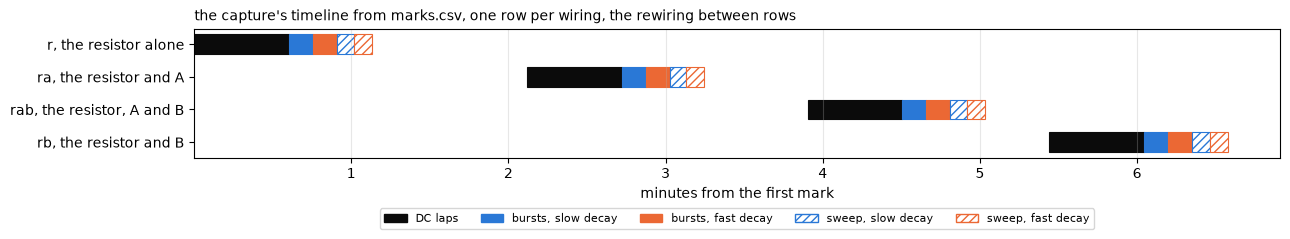

each wiring from its first mark to done, r 68 s, ra 68 s, rab 68 s, rb 69 s. The whole capture 6.6 min


In [2]:
marks = pd.read_csv(CAPTURE / "marks.csv")
marks["wiring"] = marks["mark"].str.split("/").str[0]
marks["part"] = marks["mark"].str.split("/").str[1]
t0 = marks["t_host"].iloc[0]
PART_COLOR = {"laps": INK, "bursts-slow": BLUE, "bursts-fast": ORANGE, "sweep-slow": BLUE, "sweep-fast": ORANGE}
fig, ax = plt.subplots(figsize=(13, 2.8))
for j, w in enumerate(WIRINGS):
    g = marks[marks["wiring"] == w].reset_index(drop=True)
    for i in range(len(g) - 1):                                          # each part runs from its mark to the next one
        part = g.loc[i, "part"]
        if part not in PART_COLOR:
            continue
        x, width = (g.loc[i, "t_host"] - t0) / 60, (g.loc[i + 1, "t_host"] - g.loc[i, "t_host"]) / 60
        sweep = part.startswith("sweep")                                 # sweeps hatched, bursts filled
        ax.barh(j, width, left=x, height=0.6, color="white" if sweep else PART_COLOR[part], edgecolor=PART_COLOR[part],
                hatch="////" if sweep else None, lw=0.8)
ax.set_yticks(range(len(WIRINGS)), [f"{w}, {d}" for w, d in WIRINGS.items()]); ax.invert_yaxis()
ax.set_xlabel("minutes from the first mark"); ax.grid(alpha=0.3, axis="x")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=INK, label="DC laps"), plt.Rectangle((0, 0), 1, 1, color=BLUE, label="bursts, slow decay"),
                   plt.Rectangle((0, 0), 1, 1, color=ORANGE, label="bursts, fast decay"),
                   plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=BLUE, hatch="////", label="sweep, slow decay"),
                   plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor=ORANGE, hatch="////", label="sweep, fast decay")],
          fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.set_title("the capture's timeline from marks.csv, one row per wiring, the rewiring between rows", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
dur = marks.groupby("wiring", sort=False)["t_host"].agg(lambda t: t.iloc[-1] - t.iloc[0])
print("each wiring from its first mark to done, " + ", ".join(f"{w} {d:.0f} s" for w, d in dur.items())
      + f". The whole capture {(marks['t_host'].iloc[-1] - t0) / 60:.1f} min")

Each wiring took a little over a minute, most of it the laps, and the rewiring between wirings under a minute. The bursts and the sweeps of one wiring came within about 30 s of each other, on the same rail.

### The bursts

Every burst of both decays, with the decay each folder's `meta.json` reports checked against the folder's name.

In [3]:
import json
rows = []
for w in WIRINGS:
    for decay in ("slow", "fast"):
        folder = CAPTURE / w / f"bursts-{decay}"
        meta_decay = json.loads((folder / "meta.json").read_text())["decay"]   # the decay the tool reports it ran
        BOARD.check_meta(json.loads((folder / "meta.json").read_text()), str(results.rel(folder)))   # the capture's sense block against the board entry
        for k, df in enumerate(bu.load(folder)):
            m = bu.meta(df)
            rows.append({"wiring": w, "decay": decay, "meta_decay": meta_decay, "k": k,
                         "pct": int(round(abs(m["step_q15"]) * 100 / 32768)), "sign": 1 if m["step_q15"] > 0 else -1,
                         "samples": len(df), "step_index": m["step_index"], "frame_len": m["frame_len"], "vmotor_bias": m["vmotor_bias"],
                         "rail_v": float(BOARD.rail_v(m["vbus_raw"])), "df": df})
B = pd.DataFrame(rows)
B["set"] = B["k"] // 5                                                  # five repeats of one duty and sign make a set
B["first"] = B["k"] % 5 == 0                                            # the first burst of its set
assert (B["decay"] == B["meta_decay"]).all()                            # every folder ran the decay its name says
DUTIES = sorted(B["pct"].unique())
order = B[(B["wiring"] == "r") & (B["decay"] == "slow")].groupby("set").first()
print(f"{len(B)} bursts, {B.groupby(['wiring', 'decay']).size().min()} per wiring and decay, {B['samples'].min()} to {B['samples'].max()} samples, "
      f"frame of {B['frame_len'].min()}, step at sample {B['step_index'].min()} to {B['step_index'].max()}, rail {B['rail_v'].min():.2f} to {B['rail_v'].max():.2f} V before the arm")
print("the sets in capture order, " + ", ".join(f"{r['pct']} % {'forward' if r['sign'] > 0 else 'reverse'}" for _, r in order.iterrows()))

160 bursts, 20 per wiring and decay, 960 to 960 samples, frame of 4, step at sample 484 to 484, rail 4.99 to 5.01 V before the arm
the sets in capture order, 25 % forward, 25 % reverse, 40 % forward, 40 % reverse


All 160 bursts have the same length and frame and the step at the same sample, on a rail within 20 mV of 5.0 V. The sets of five ran in the same order in every folder, so each set's first burst follows a change of sign. The slow set's first burst follows the reverse direction of the last lap, and the fast set's first burst follows the last slow burst at 40 % reverse.

### One burst of each decay

The second burst of the 25 % forward set on `ra`, in slow decay on the left and fast decay on the right. On top the shunt over its own zero, the median of its samples before the step, through the current-scale scale. Underneath each tap as an absolute terminal voltage against the bias node.

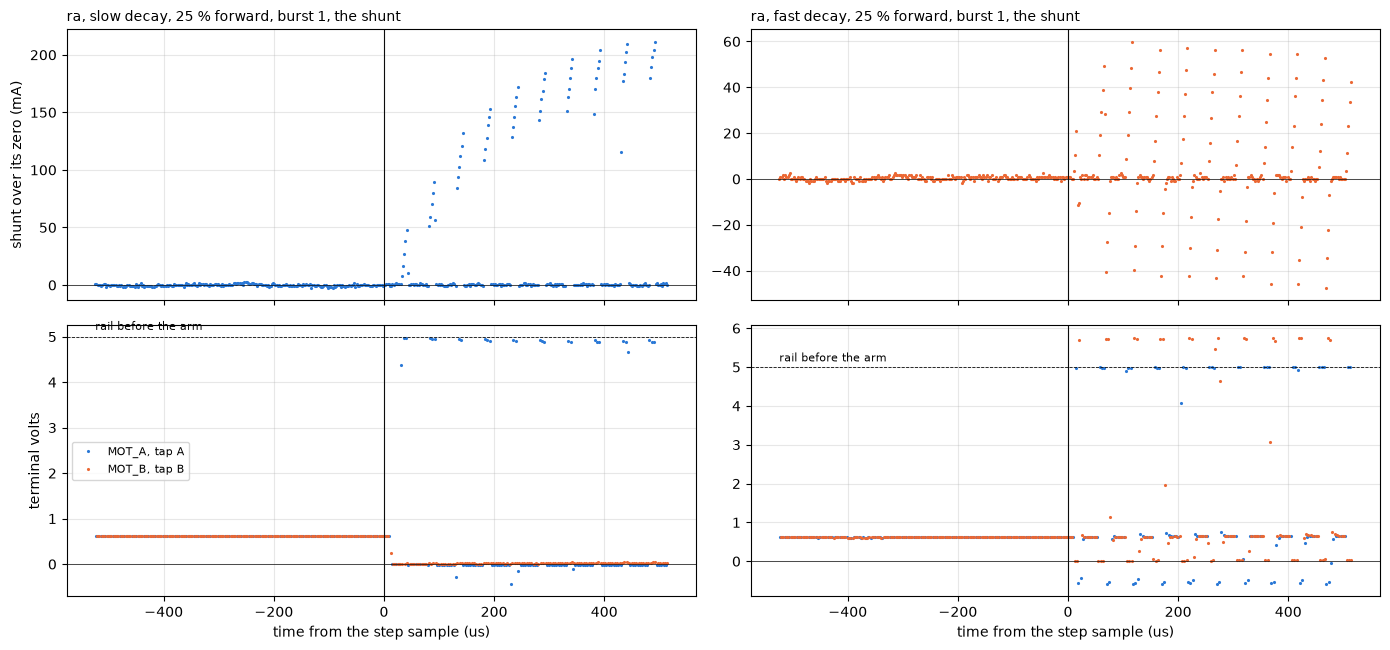

In [4]:
def amps_over_zero(df):
    # the shunt samples over the burst's own zero in mA, the zero being the median of the shunt before the step
    return (df["code"].to_numpy(float) - bu.zero(df, ARR)) / COUNTS_PER_A * 1e3

def terminal_v(code, vb):
    # one tap's absolute terminal volts against the bias node, the divider undone
    return BOARD.term_v(code, vb)

fig, ax = plt.subplots(2, 2, figsize=(14, 6.6), sharex=True)
for col, decay in enumerate(("slow", "fast")):
    e = B[(B["wiring"] == "ra") & (B["decay"] == decay) & (B["pct"] == 25) & (B["sign"] > 0)].iloc[1]   # the second burst of the set
    df = e["df"]
    m, ph, sh, ta, tb = bu.phase(df, ARR)
    t = (np.arange(len(df)) - m["step_index"]) * US                     # microseconds from the step sample
    i = amps_over_zero(df)
    ax[0, col].plot(t[sh], i[sh], ".", ms=2.5, color=BLUE if decay == "slow" else ORANGE)
    ax[0, col].set_title(f"ra, {decay} decay, 25 % forward, burst {e['k']}, the shunt", loc="left", fontsize=10)
    y = df["code"].to_numpy(float)
    ax[1, col].plot(t[ta], terminal_v(y[ta], e["vmotor_bias"]), ".", ms=2.5, color=BLUE, label="MOT_A, tap A")
    ax[1, col].plot(t[tb], terminal_v(y[tb], e["vmotor_bias"]), ".", ms=2.5, color=ORANGE, label="MOT_B, tap B")
    ax[1, col].axhline(e["rail_v"], color=INK, lw=0.6, ls="--"); ax[1, col].text(t[0], e["rail_v"] + 0.15, "rail before the arm", fontsize=8)
    ax[1, col].set_xlabel("time from the step sample (us)")
    for a in ax[:, col]:
        a.axvline(0, color=INK, lw=0.8); a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3)
ax[0, 0].set_ylabel("shunt over its zero (mA)"); ax[1, 0].set_ylabel("terminal volts"); ax[1, 0].legend(fontsize=8, loc="center left")
plt.tight_layout(); plt.show()

Before the step both taps read the bias node, about 0.62 V, and the shunt its zero.

In slow decay the shunt reads a pulse in every window, and the level the pulse sits at climbs from window to window toward about 200 mA. Between windows it reads its zero. Inside each window tap A is the driven terminal near the rail and tap B the return near ground, and between windows both sit near ground, the load shorted through the low side.

In fast decay the shunt rises inside each window and then reads below its zero, by about as much as it rose, after every window, and the peak does not climb from period to period. Between windows one tap sits about 0.75 V over the rail and the other about 0.6 V under ground, and then both go back to the bias node until the next window. The next sections take each of these apart, one period at a time.

## Method

### DC resistance

Each lap gives the wiring's $V / I$ at 100 %, the tap difference through the terminal-chain line over the counts through the current-scale line, the lap's own torque-off zero taken off. The two directions give two readings per lap. The difference of two wirings at the same rail takes off the resistor and every error the two laps share, and leaves the part that was added plus the Dupont joint that came with it. Each inductor has two such routes, A as `ra` less `r` and as `rab` less `rb`, B as `rb` less `r` and as `rab` less `ra`, so the spread of the routes is the size of what the joints and the rewiring add.

### The burst method, unchanged

The slow-decay bursts are read with the inductance notebook's code, copied below, unchanged in how it reads a burst.

- The current $i_n$ of each full period is a line through the window's settled shunt samples, evaluated at the middle of the bridge's window, less the in-drive offset of current-scale.
- The volts $V_n$ each period applied are the tap difference over the window and over the time between windows, weighted by their durations, plus what the two edges hold beyond that two-part mean, pooled per wiring, duty and sign.
- $R$ and $L$ come from one least squares over the burst's period pairs,

$$L\,(i_{n+1} - i_n) = T\left(V_n - R\,\frac{i_n + i_{n+1}}{2}\right)$$

with $T$ the 50 us period, and $\tau = L / R$.
- The window's own inductance is $L_\mathrm{ripple} = (V_\mathrm{on} - R\,i_n) / (di/dt)_\mathrm{window}$, the median of the last three periods.
- $R$ and $L$ are divided by the window's scale $k$, the window's $V_\mathrm{on} / i$ on the bare resistor over the same resistor's 100 % laps.
- Every summary takes the bursts after the first of each set, and the first burst is read on its own against its set.

The one change is where $k$ comes from. The inductance notebook took it from sample-timing's bursts on the bare load over current-scale's laps, two captures with two different wirings. Here `r` is in the same capture, on the same rail and the same pigtails, so $k$ comes from `r`'s own slow bursts over `r`'s own laps. $k$ divides $R$, $L$ and $L_\mathrm{ripple}$ alike, so the ratio of the ripple to the fit, the number this notebook is after, does not depend on it.

On `r` the current stops at the end of each window, since nothing stores it. The period equation assumes a current that carries from one window into the next, so on `r` the fitted $R$ reads the duty's share of the resistance and the fitted $L$ reads whatever the window ramps leave, which should be close to zero.

### The fast-decay ramp

Below 50 % duty in fast decay the current falls back to zero before the next window on every load here, so every period starts from zero. The shunt then sees a ramp that starts at zero, with no step for the amplifier to settle from, which is the slow-decay window's weak spot. The line through the window's settled shunt samples gives the slope, the taps give $V_\mathrm{on}$, and

$$L_\mathrm{fast} = \frac{V_\mathrm{on} - R\,i_\mathrm{mid}}{(di/dt)_\mathrm{window}}$$

with $R$ the wiring's DC resistance and $i_\mathrm{mid}$ the current at the window's middle, divided by $k$ as the slow readings are. It is a third reading of the same inductance, from a window with a different history before it.

### The sweeps

The sweep rows are the settled state that a burst ends before. Each rung's crest and trough rows are read over the sweep's torque-off zero less the in-drive offset, so a reading of zero current reads about zero. In slow decay the window sits on the crest, so the crest row should read the load current and the trough row zero. In fast decay the window sits on the trough, so the trough row should read the ramp at the middle of the window and the crest row zero. At 100 % nothing switches and the two rows should agree. The bursts predict two of these rows on the inductive wirings. The slow fit's settled current is the period's mean volts over $R$, and the fast fold reads the ramp at the trough.

### The fast-decay edges

The fast-decay folds of `r` and `ra`, every burst's shunt samples placed against the ticks from the trough and binned in 4 ticks, are fitted with a model of the bridge and the load run tick by tick. Inside the window the bridge drives the window's volts through a small on resistance. Outside it the current returns to the rail through the body diodes at the return's measured level, and once that current runs out the bridge floats with all four switches off. The load is the wiring's DC resistance in series with its inductance, `ra`'s from its fast-decay ramp and a token 1 uH on `r`, with 50 pF across the terminals. Its state is stepped through one timer tick exactly with the matrix exponential, so a fast edge into a small capacitance stays stable. The shunt amplifier is a first-order lag with a gain. On `r` and `ra` at 25 and 40 %, the amplifier's lag and gain are fitted on the rising edge and the window for each candidate ON lag from 4 to 44 ticks in steps of 2, and the lag with the least misfit is kept. Then the OFF lag is scanned from 0 to 30 ticks on `ra`'s OFF edge and return with the amplifier held. Each bin counts over its standard error of the median, at least 0.3 mA.

### The code

`samples` places every sample of a burst on a window-aligned period grid, with the window's center at the crest for slow decay and at the trough for fast decay. The duty written at the step takes effect at the next trough, so in fast decay the window centered on that trough holds only its second half, and the grid starts one period later, at the first full window. `periods` is the inductance notebook's function, which here also records the window's lowest and highest shunt code for a check below.

In [5]:
def samples(df, center="crest"):
    # one row per sample: its stream, its code, the tick its aperture closed on an unwrapped axis, its phase from the center of
    # the drive window (the crest in slow decay, the trough in fast), and its period on a grid that starts at the first full
    # commanded window after the step. The duty written at the step takes effect at the next trough, so the grid starts at the
    # crest window after it in slow decay and at the trough window one period later in fast decay, where the first trough's
    # window is only its second half
    m, ph, sh, ta, tb = bu.phase(df, ARR)
    half = int(BOARD.drive_ticks(m["step_q15"]))                          # the window's half-width in ticks
    k = np.arange(len(df))
    phi0 = m["start_cnt"] if m["start_dir"] == 0 else PERIOD - m["start_cnt"]   # the counter's phase at the first sample, 0 at the trough
    tick = phi0 + bu.STEP_TICKS * k + bu.APERTURE_CLK * bu.TICKS_PER_ADC_CLK   # when each aperture closed, never wrapped
    trough = PERIOD * np.ceil(tick[m["step_index"]] / PERIOD)              # the first trough after the step sample
    c = ARR if center == "crest" else PERIOD                                # the first full window's center after that trough
    origin = trough + c - half                                             # its commanded start
    n = np.floor((tick - origin) / PERIOD).astype(int)                     # period index on the window-aligned grid, negative before it
    last = int(np.floor((tick[-1] - origin) / PERIOD))                     # the partial period at the end is dropped
    tc = ((tick - c) % PERIOD + PERIOD // 2) % PERIOD - PERIOD // 2        # ticks from the nearest window center
    stream = np.where(sh, "sh", np.where(ta, "ta", "tb"))
    s = pd.DataFrame({"k": k, "stream": stream, "code": df["code"].to_numpy(float), "tick": tick, "tc": tc, "n": n,
                      "t_us": (tick - origin) / bu.TICKS_PER_US, "full": n < last})
    return s, m, half

def periods(df, sign, edge=0.0):
    # the inductance notebook's reading of a slow-decay burst, unchanged: one row per full period after the step, the winding
    # current at the middle of the bridge's window, the volts the period applied, the window's own volts and slope, and what the
    # shunt reads between windows. `edge` is the volt-ticks the two edges hold beyond the two-part mean
    s, m, half = samples(df)
    zero = bu.zero(df, ARR)                                                # the amplifier's zero from the pre-step shunt samples
    a, b = -half + TAP_ON_LAG, half + OFF_LAG                              # the bridge's ON and OFF edges in ticks from the crest
    on_span = b - a                                                        # ticks the bridge drives in each period
    s = s[(s["n"] >= 0) & s["full"]].assign(y=lambda d: d["code"] - zero)
    settled = (s["tc"] >= -half + SETTLE) & (s["tc"] <= half)              # inside the window, after the amplifier's settle, before the OFF edge
    clear = (s["tc"] >= b + SETTLE - ON_LAG) | (s["tc"] <= -half - 10)    # between windows, clear of the OFF edge's tail and before the next start
    rows = []
    for n, g in s.groupby("n"):
        sh = g[(g["stream"] == "sh") & settled[g.index]]
        line = np.polyfit(sh["tc"], sh["y"], 1)                            # the ramp inside the window, a line over the settled samples
        i_on = (np.polyval(line, (a + b) / 2) - DRIVE_OFF) / COUNTS_PER_A  # at the window's middle, less the in-drive offset, in amps
        i_off = g[(g["stream"] == "sh") & clear[g.index]]["y"].mean() / COUNTS_PER_A   # the shunt between windows, in amps
        d_on, d_off = ((g[(g["stream"] == "ta") & w[g.index]]["code"].mean() - g[(g["stream"] == "tb") & w[g.index]]["code"].mean())
                       for w in (settled, clear))                          # tap A less tap B, inside the window and between windows
        v_on, v_off = ((sign * d - TERM_OFF) / COUNTS_PER_V for d in (d_on, d_off))   # the terminal-chain line inverted, signed by the step
        rows.append({"n": n, "t_us": (n * PERIOD + half + (a + b) / 2) / bu.TICKS_PER_US,
                     "i_a": i_on, "v_v": (v_on * on_span + v_off * (PERIOD - on_span) + edge) / PERIOD,
                     "v_on_v": v_on, "v_off_v": v_off, "i_off_a": i_off,
                     "slope_a_per_s": line[0] * bu.TICKS_PER_US * 1e6 / COUNTS_PER_A, "on_n": len(sh),
                     "code_lo": sh["code"].min(), "code_hi": sh["code"].max()})   # the window's shunt codes, for the carry check below
    return pd.DataFrame(rows)

SLOW, FAST = B[B["decay"] == "slow"], B[B["decay"] == "fast"]

## Results

### DC resistance

Each lap's $V / I$, both directions, by wiring and rail. Beside it, the raw current codes of two of the 4.2 V laps. The thing to see is the `r` lap at 4.2 V, which sits apart from its 3.7 V lap by more than any other wiring does.

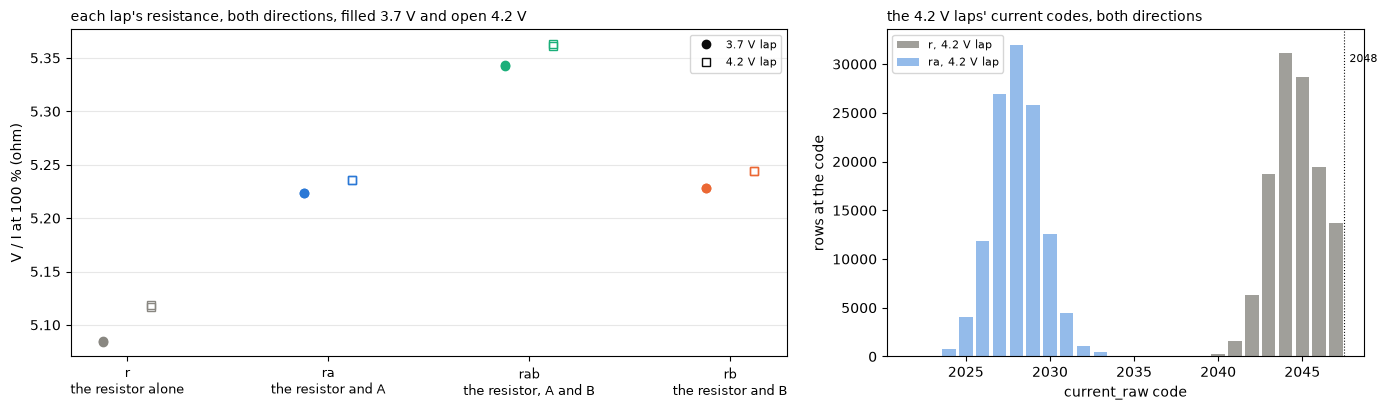

                   r_ohm  spread_mohm     i_a  code_max
wiring volts_set                                       
r      3.7        5.0847       0.6297  0.6492      1953
       4.2        5.1177       1.6991  0.7351      2047
ra     3.7        5.2237       0.3471  0.6332      1934
       4.2        5.2359       0.3008  0.7205      2035
rab    3.7        5.3431       1.4063  0.6208      1921
       4.2        5.3618       2.0728  0.7053      2018
rb     3.7        5.2281       0.3466  0.6331      1935
       4.2        5.2441       0.7293  0.7199      2036


In [6]:
# one row per lap and direction: the settled means over the lap, its own torque-off zero, and the lap's V and I through the stage 1 lines
L = pd.concat([laps.table(CAPTURE / w, BOARD).assign(wiring=w) for w in WIRINGS], ignore_index=True)
L["i_a"] = (L["current_raw"] - L["zero"] - DRIVE_OFF) / COUNTS_PER_A           # current-scale's line inverted
L["v_v"] = ((L["vmotor_a"] - L["vmotor_b"]) * L["dir"] - TERM_OFF) / COUNTS_PER_V   # terminal-chain's line inverted, signed by the direction
L["r_ohm"] = L["v_v"] / L["i_a"]

# the raw current codes of every lap, to see where each lap's reading sits on the converter
codes = {}
for w in WIRINGS:
    for k in (0, 1):
        d, _ = tel.load(CAPTURE / w / "laps" / str(k), BOARD)
        codes[(w, k)] = pd.concat([tel.settled(g) for _, g in d[d["seg"] > 0].groupby("seg")])["current_raw"]
L["code_max"] = [codes[(r["wiring"], r["k"])].max() for _, r in L.iterrows()]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 2]})
for j, w in enumerate(WIRINGS):
    for lvl, dx in ((3.7, -0.12), (4.2, 0.12)):
        g = L[(L["wiring"] == w) & (L["volts_set"] == lvl)]
        ax[0].plot([j + dx] * len(g), g["r_ohm"], "o" if lvl < 4 else "s", ms=6, color=COLOR[w], mfc=COLOR[w] if lvl < 4 else "none",
                   label=f"{lvl} V rail" if j == 0 else None)
ax[0].set_xticks(range(len(WIRINGS)), [f"{w}\n{d}" for w, d in WIRINGS.items()], fontsize=9)
ax[0].set_ylabel("V / I at 100 % (ohm)"); ax[0].grid(alpha=0.3, axis="y")
ax[0].set_title("each lap's resistance, both directions, filled 3.7 V and open 4.2 V", loc="left", fontsize=10)
ax[0].legend(handles=[Line2D([], [], ls="none", marker="o", color=INK, label="3.7 V lap"), Line2D([], [], ls="none", marker="s", mfc="none", color=INK, label="4.2 V lap")], fontsize=8)
for (w, k), ls in ((("r", 1), "-"), (("ra", 1), "--")):
    h = codes[(w, k)].value_counts().sort_index()
    ax[1].bar(h.index, h.to_numpy(), width=0.8, color=COLOR[w], alpha=0.8 if w == "r" else 0.5, label=f"{w}, 4.2 V lap")
ax[1].axvline(2047.5, color=INK, lw=0.8, ls=":"); ax[1].text(2047.8, ax[1].get_ylim()[1] * 0.9, "2048", fontsize=8)
ax[1].set_xlabel("current_raw code"); ax[1].set_ylabel("rows at the code"); ax[1].legend(fontsize=8, loc="upper left")
ax[1].set_title("the 4.2 V laps' current codes, both directions", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(L.groupby(["wiring", "volts_set"], sort=False).agg(r_ohm=("r_ohm", "mean"), spread_mohm=("r_ohm", lambda x: (x.max() - x.min()) * 1e3),
                                                        i_a=("i_a", "mean"), code_max=("code_max", "max")).round(4).to_string())

At 3.7 V the four wirings read 5.085, 5.224, 5.343 and 5.228 ohm, and the two directions of each lap agree to under 1.5 mOhm. The 4.2 V laps of `ra`, `rab` and `rb` read 12 to 19 mOhm over their 3.7 V laps, 0.2 to 0.35 %, about the size of current-scale's residual at these currents. The `r` lap at 4.2 V reads 33 mOhm over its 3.7 V lap. Its current codes stop at 2047 with no row above it, where a spread like `ra`'s around its mean would put a good share of the rows over 2047. Its current is read low by the converter, a section below shows why, and that lap is left out. The DC resistance of each wiring is its 3.7 V laps.

The `r` wiring reads 0.14 % under the bare resistor's stage 0 value, 5.092 ohm without its leads, where the pigtails and the connector add to it. The terminal chain is graded to about 0.1 % against the meter. The current chain's 0.1 % is the statistical spread of current-scale's line, and its absolute class is 2 % of the reading, the class of the DMM's 20 A jack it was graded on. So the two agree within what the chains carry, and a 0.14 % difference cannot be read finer than that 2 %.

### Each inductor's copper

Each inductor as the difference of two wirings, every route at each rail where both laps count.

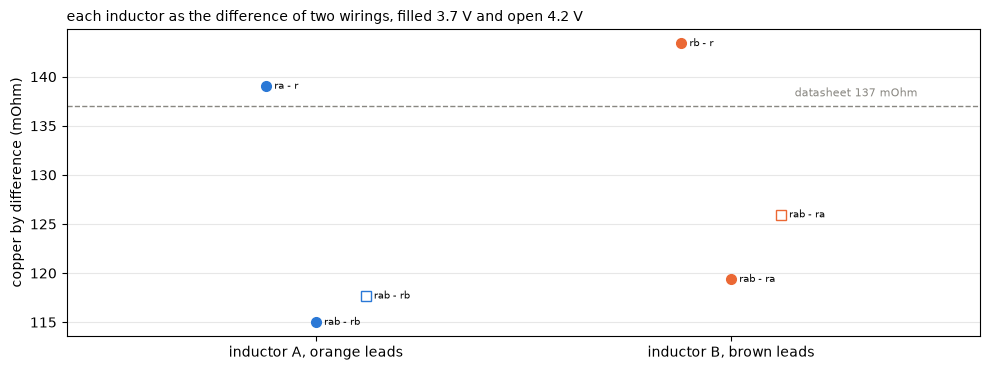

inductor A, ra - r at 3.7 V 139.0, rab - rb at 3.7 V 115.0, rab - rb at 4.2 V 117.7 mOhm, median 117.7
inductor B, rb - r at 3.7 V 143.4, rab - ra at 3.7 V 119.4, rab - ra at 4.2 V 126.0 mOhm, median 126.0
(ra + rb) - (rab + r) at 3.7 V +24.0 mOhm, zero if the joints and parts added exactly
r at 3.7 V 5.0847 ohm against the bare resistor's stage 0 value 5.0916 ohm without its leads, -0.14 %


In [7]:
# the r lap at 4.2 V sits against code 2047 and is left out, every other lap counts
L["ok"] = ~((L["wiring"] == "r") & (L["volts_set"] == 4.2))
R_DC = L[L["volts_set"] == 3.7].groupby("wiring")["r_ohm"].mean().to_dict()            # each wiring's DC resistance, the 3.7 V laps
R_DC_LO = L[L["ok"]].groupby("wiring")["r_ohm"].min().to_dict()
R_DC_HI = L[L["ok"]].groupby("wiring")["r_ohm"].max().to_dict()
lvl = L[L["ok"]].groupby(["wiring", "volts_set"])["r_ohm"].mean()           # direction mean per wiring and level

# each inductor's copper by difference, two routes each at 3.7 V and the route without r at 4.2 V
ROUTES = {"A": [("ra", "r"), ("rab", "rb")], "B": [("rb", "r"), ("rab", "ra")]}
rows = []
for ind, pairs in ROUTES.items():
    for hi_, lo_ in pairs:
        for v in (3.7, 4.2):
            if (hi_, v) in lvl and (lo_, v) in lvl:
                rows.append({"inductor": ind, "route": f"{hi_} - {lo_}", "level": v, "dcr_ohm": lvl[(hi_, v)] - lvl[(lo_, v)]})
DCR = pd.DataFrame(rows)
ADD = (lvl[("ra", 3.7)] + lvl[("rb", 3.7)]) - (lvl[("rab", 3.7)] + lvl[("r", 3.7)])   # A and B alone against A and B together, 3.7 V

fig, ax = plt.subplots(figsize=(10, 3.8))
for x, (ind, g) in enumerate(DCR.groupby("inductor")):
    for j, (_, r) in enumerate(g.iterrows()):
        ax.plot(x + (j - (len(g) - 1) / 2) * 0.12, r["dcr_ohm"] * 1e3, "o" if r["level"] < 4 else "s", ms=7,
                color=BLUE if ind == "A" else ORANGE, mfc=(BLUE if ind == "A" else ORANGE) if r["level"] < 4 else "none")
        ax.annotate(r["route"], (x + (j - (len(g) - 1) / 2) * 0.12, r["dcr_ohm"] * 1e3), xytext=(6, 0), textcoords="offset points", fontsize=7, va="center")
ax.axhline(DCR_NOM_OHM * 1e3, color=MUTED, lw=1, ls="--"); ax.text(1.45, DCR_NOM_OHM * 1e3 + 1, "datasheet 137 mOhm", fontsize=8, color=MUTED, ha="right")
ax.set_xticks([0, 1], ["inductor A, orange leads", "inductor B, brown leads"]); ax.set_xlim(-0.6, 1.6)
ax.set_ylabel("copper by difference (mOhm)"); ax.grid(alpha=0.3, axis="y")
ax.set_title("each inductor as the difference of two wirings, filled 3.7 V and open 4.2 V", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for ind, g in DCR.groupby("inductor"):
    print(f"inductor {ind}, " + ", ".join(f"{r['route']} at {r['level']} V {r['dcr_ohm'] * 1e3:.1f}" for _, r in g.iterrows())
          + f" mOhm, median {g['dcr_ohm'].median() * 1e3:.1f}")
print(f"(ra + rb) - (rab + r) at 3.7 V {ADD * 1e3:+.1f} mOhm, zero if the joints and parts added exactly")
print(f"r at 3.7 V {R_DC['r']:.4f} ohm against the bare resistor's stage 0 value {PR['bare']['r_cold']['value']:.4f} ohm without its leads, "
      f"{(R_DC['r'] / PR['bare']['r_cold']['value'] - 1) * 100:+.2f} %")

The two routes disagree by more than the laps' own scatter. Through `r` the inductors read 139 and 143 mOhm, through `rab` 115 to 126 mOhm, and $(ra + rb) - (rab + r)$, which is zero when every part and joint adds the same in each wiring, comes out at +24 mOhm. A Dupont joint is a few tens of milliohms, rewired four times, so the spread most likely belongs to the joints, with moderate confidence. Each inductor's copper is therefore known to about 25 mOhm. The medians, 118 mOhm for A and 126 mOhm for B, sit under the datasheet's 137 mOhm, and the routes through `r` sit over it. This capture does not separate the copper from the joints any better, and the open questions name what would.

### Code 2047

The fast-decay return puts one tap over the rail, close to code 2048, and the `r` lap at 4.2 V put its current there too. Every burst sample from 2030 to 2070, all wirings and both decays together.

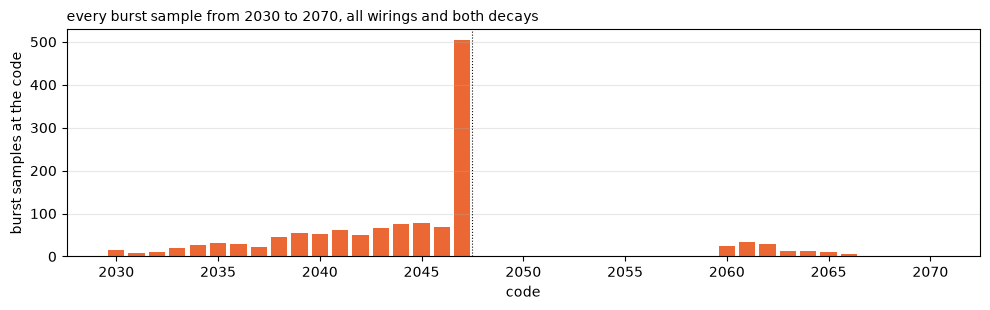

code 2047 holds 504 samples against 64 per code from 2040 to 2046 and 20 from 2060 to 2065. Never read: 2048 to 2059, 12 codes


In [8]:
# every burst sample near the 2048 carry, all wirings and both decays: the fast return's tap above the rail lands here
allc = np.concatenate([e["df"]["code"].to_numpy(int) for _, e in B.iterrows()])
near = pd.Series(allc[(allc >= 2030) & (allc <= 2070)]).value_counts().reindex(range(2030, 2071), fill_value=0)
first_seen = min(c for c in range(2048, 2071) if near[c] > 0)          # the first code above 2047 the converter produced
MISSING_2048 = list(range(2048, first_seen))                             # the codes between that it never produced
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(near.index, near.to_numpy(), width=0.8, color=ORANGE)
ax.axvline(2047.5, color=INK, lw=0.8, ls=":")
ax.set_xlabel("code"); ax.set_ylabel("burst samples at the code"); ax.grid(alpha=0.3, axis="y")
ax.set_title("every burst sample from 2030 to 2070, all wirings and both decays", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(f"code 2047 holds {near[2047]} samples against {near.loc[2040:2046].mean():.0f} per code from 2040 to 2046 and {near.loc[2060:2065].mean():.0f} from 2060 to 2065. "
      f"Never read: {MISSING_2048[0]} to {MISSING_2048[-1]}, {len(MISSING_2048)} codes")

Code 2047 holds eight times as many samples as its neighbors below it, and the converter never produced codes 2048 to 2059. It holds 2047 over about a dozen codes of input and then skips. Terminal-chain found the same shape at the 1024 carry, a code 1023 held over about ten codes with the codes above it missing, and current-scale saw the 4.2 V laps at code 2046 sit under its line. This is the 2048 carry doing what the 1024 carry does, with high confidence. Any reading that lands within a dozen codes over 2047 reads 2047, and a mean over readings that straddle it reads low. In this capture that is the `r` lap at 4.2 V and the fast-decay return tap, and nothing else comes near it.

### The window's scale on the resistor

The bare resistor read inside the slow-decay window, every `r` burst, against the same wiring's laps.

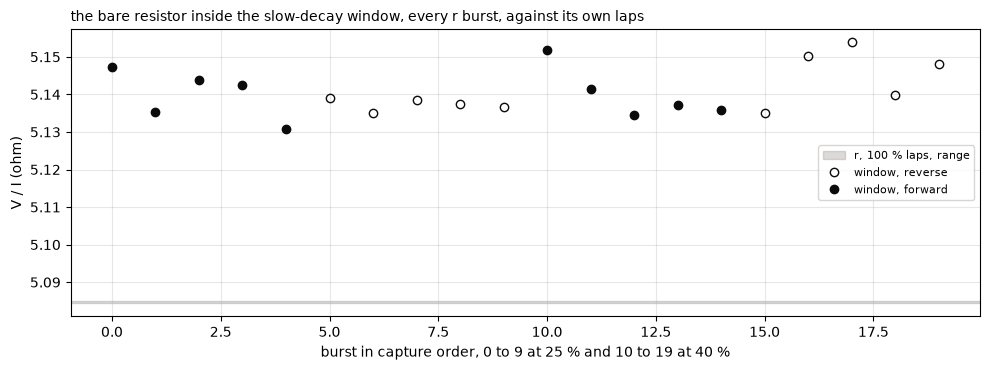

window 5.139 ohm (5.131 to 5.154) at 0.866 A, laps 5.085 ohm. k = 1.0106 (1.0091 to 1.0136)
sample-timing's bursts into the bare load read 5.406 ohm inside the window (5.379 to 5.431) over 36 bursts, +5.2 % against r's window here
the window's slope on r, 25 % -1284 A/s, -1483 A/s per amp of level, 40 % +587 A/s, +677 A/s per amp of level


In [9]:
# the window's V/I on the bare resistor, every slow burst of r, the first period left out as the rail takes the step
rows = []
for _, e in SLOW[SLOW["wiring"] == "r"].iterrows():
    P = periods(e["df"], e["sign"]).iloc[1:]
    rows.append({"pct": e["pct"], "sign": e["sign"], "k": e["k"], "r_ohm": P["v_on_v"].median() / P["i_a"].median(),
                 "i_a": P["i_a"].median(), "v_on_v": P["v_on_v"].median(), "slope_a_per_s": P["slope_a_per_s"].median()})
RW = pd.DataFrame(rows)
K = RW["r_ohm"].median() / R_DC["r"]                                   # the window's scale over r's own 100 % laps in this capture
K_LO, K_HI = RW["r_ohm"].min() / R_DC["r"], RW["r_ohm"].max() / R_DC["r"]
# sample-timing's bursts into the bare load, read the same way, 15 % and up as the inductance notebook reads them
ST_BURSTS = (Path("../../../telemetry") / BOARD.key / "sample-timing" / "capture-1").resolve()
st = []
for folder in ("bursts", "bursts-1s"):
    for df_s in bu.load(ST_BURSTS / folder):
        m_s = bu.meta(df_s)
        if abs(m_s["step_q15"]) * 100 / 32768 >= 14.5:
            P = periods(df_s, 1 if m_s["step_q15"] > 0 else -1).iloc[1:]
            st.append(P["v_on_v"].median() / P["i_a"].median())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axhspan(R_DC_LO["r"], R_DC_HI["r"], color=MUTED, alpha=0.3, label="r, 100 % laps, range")
for (pct, sgn), g in RW.groupby(["pct", "sign"]):
    ax.plot(g["k"], g["r_ohm"], "o", ms=6, color=INK, mfc=INK if sgn > 0 else "none", ls="none", label=f"window, {'forward' if sgn > 0 else 'reverse'}" if pct == 25 else None)
ax.set_xlabel("burst in capture order, 0 to 9 at 25 % and 10 to 19 at 40 %"); ax.set_ylabel("V / I (ohm)"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="center right")
ax.set_title("the bare resistor inside the slow-decay window, every r burst, against its own laps", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(f"window {RW['r_ohm'].median():.3f} ohm ({RW['r_ohm'].min():.3f} to {RW['r_ohm'].max():.3f}) at {RW['i_a'].median():.3f} A, laps {R_DC['r']:.3f} ohm. "
      f"k = {K:.4f} ({K_LO:.4f} to {K_HI:.4f})")
print(f"sample-timing's bursts into the bare load read {np.median(st):.3f} ohm inside the window ({min(st):.3f} to {max(st):.3f}) over {len(st)} bursts, "
      f"{(np.median(st) / RW['r_ohm'].median() - 1) * 100:+.1f} % against r's window here")
print("the window's slope on r, " + ", ".join(f"{p} % {g['slope_a_per_s'].median():+.0f} A/s, {g['slope_a_per_s'].median() / g['i_a'].median():+.0f} A/s per amp of level"
                                              for p, g in RW.groupby("pct")))

The window reads `r` at 5.139 ohm, 5.131 to 5.154 over twenty bursts with no trend in duty or sign, against 5.085 ohm on the laps. So $k$ is 1.011, known to about 0.3 %. Read the same way, sample-timing's bursts on the bare load put the same resistor at 5.38 to 5.43 ohm inside the window, 5 % over its window here. Sample-timing reads its own $k$ on that wiring, its window over its own 100 % rungs, and it lands with this one, below, so the 5 % belongs to the two wirings and not to the window. Here it costs nothing, since $k$ cancels in the ratio of the ripple to the fit, and the fast-decay ramp below gives an inductance that agrees with the fit at this $k$.

The window's own slope on a resistor is not zero. At 25 % the shunt falls through the window by about 1300 A/s at 0.87 A, and at 40 % it rises by about 600 A/s.

### Slow decay through one period

The second burst of the 40 % forward set on `r`, `ra` and `rab`, folded onto the PWM period, light to dark from the first full period to the last. On top the shunt, underneath the terminal difference, the commanded window shaded.

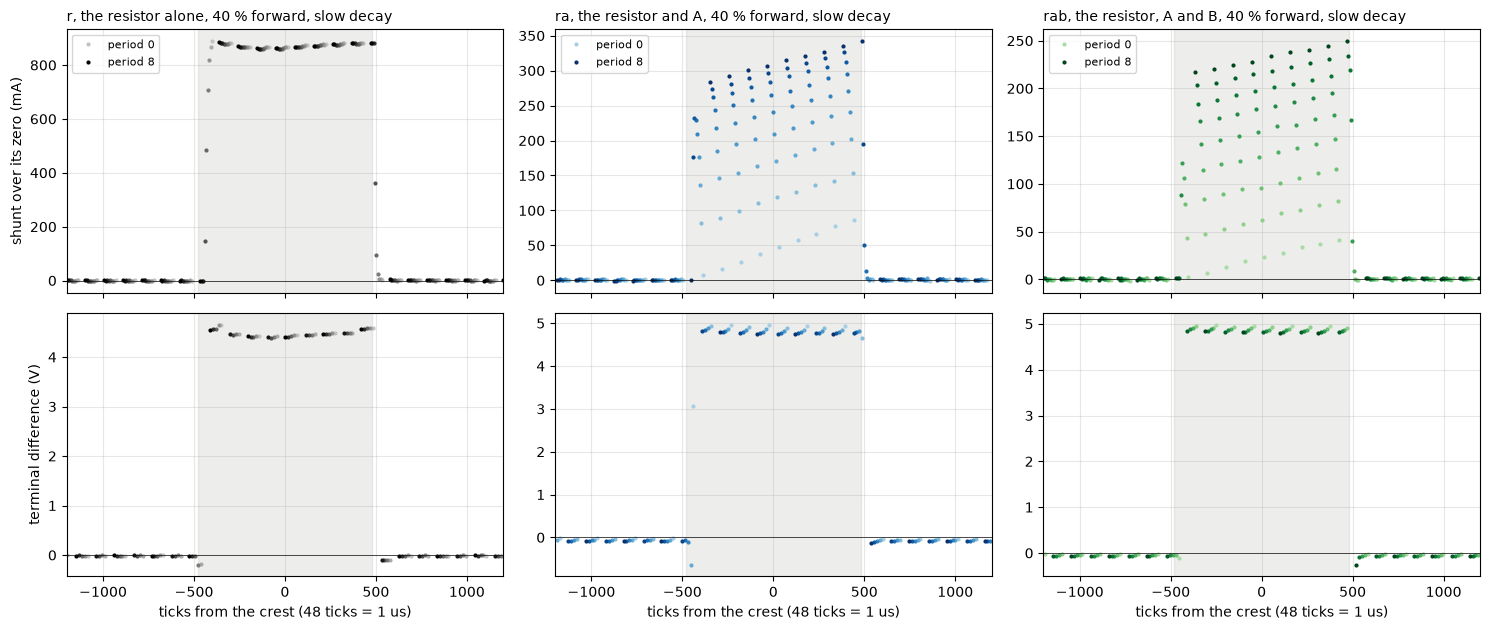

r: shunt between windows +0.68 mA (bursts -0.24 to +1.33), terminal difference between windows over the last three periods 25 % -9 mV, 40 % -10 mV
ra: shunt between windows +0.17 mA (bursts -1.05 to +0.92), terminal difference between windows over the last three periods 25 % -55 mV, 40 % -86 mV, over the window current 0.302 ohm (0.288 to 0.328)
rab: shunt between windows +0.21 mA (bursts -0.32 to +0.81), terminal difference between windows over the last three periods 25 % -42 mV, 40 % -66 mV, over the window current 0.321 ohm (0.305 to 0.352)
rb: shunt between windows +0.20 mA (bursts -0.77 to +0.89), terminal difference between windows over the last three periods 25 % -55 mV, 40 % -85 mV, over the window current 0.303 ohm (0.286 to 0.318)
terminal-chain's low-side return path 0.305 ohm


In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6.4), sharex=True)
for col, w in enumerate(("r", "ra", "rab")):
    e = SLOW[(SLOW["wiring"] == w) & (SLOW["pct"] == 40) & (SLOW["sign"] > 0)].iloc[1]   # the second burst of the 40 % forward set
    s, m, half = samples(e["df"])
    zero = bu.zero(e["df"], ARR)
    post = s[(s["n"] >= 0) & s["full"]]
    N = post["n"].max() + 1
    shade = plt.cm.Greys(np.linspace(0.35, 1.0, N)) if w == "r" else (plt.cm.Blues if w == "ra" else plt.cm.Greens)(np.linspace(0.35, 1.0, N))
    for n, g in post.groupby("n"):
        g_sh = g[g["stream"] == "sh"]
        ax[0, col].plot(g_sh["tc"], (g_sh["code"] - zero) / COUNTS_PER_A * 1e3, ".", ms=4, color=shade[n], label=f"period {n}" if n in (0, N - 1) else None)
        a_, b_ = g[g["stream"] == "ta"], g[g["stream"] == "tb"]
        vb = np.interp(a_["tick"], b_["tick"], b_["code"])                 # tap B at tap A's instant, from its two neighbors
        ax[1, col].plot(a_["tc"], (e["sign"] * (a_["code"] - vb) - TERM_OFF) / COUNTS_PER_V, ".", ms=4, color=shade[n])
    for a in ax[:, col]:
        a.axvspan(-half, half, color=MUTED, alpha=0.15)                     # the commanded window
        a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3); a.set_xlim(-ARR, ARR)
    ax[0, col].set_title(f"{w}, {WIRINGS[w]}, 40 % forward, slow decay", loc="left", fontsize=10)
    ax[1, col].set_xlabel("ticks from the crest (48 ticks = 1 us)")
    ax[0, col].legend(fontsize=8, loc="upper left")
ax[0, 0].set_ylabel("shunt over its zero (mA)"); ax[1, 0].set_ylabel("terminal difference (V)")
plt.tight_layout(); plt.show()

# what the shunt and the taps read between windows on every slow burst, against the window current of the same period
rows = []
for _, e in SLOW.iterrows():
    P = periods(e["df"], e["sign"])
    rows.append({"wiring": e["wiring"], "pct": e["pct"], "i_off_ma": P["i_off_a"].mean() * 1e3, "v_off_mv": P["v_off_v"].iloc[-3:].mean() * 1e3,
                 "i_last_a": P["i_a"].iloc[-3:].mean()})
OFF = pd.DataFrame(rows)
OFF["loop_ohm"] = -OFF["v_off_mv"] / 1e3 / OFF["i_last_a"]                 # the brake level over the current circulating through it
for w, g in OFF.groupby("wiring", sort=False):
    print(f"{w}: shunt between windows {g['i_off_ma'].mean():+.2f} mA (bursts {g['i_off_ma'].min():+.2f} to {g['i_off_ma'].max():+.2f}), "
          f"terminal difference between windows over the last three periods " + ", ".join(f"{p} % {gg['v_off_mv'].median():+.0f} mV" for p, gg in g.groupby("pct"))
          + ("" if w == "r" else f", over the window current {g['loop_ohm'].median():.3f} ohm ({g['loop_ohm'].min():.3f} to {g['loop_ohm'].max():.3f})"))
print(f"terminal-chain's low-side return path {TC['return_path_ohm']['value']:.3f} ohm")

On `r` the window is a flat step, the same in every period, and both the shunt and the terminals read zero between windows. On `ra` the shunt steps up at the ON edge to a level that climbs from period to period, ramps up through the window and drops to its zero at the OFF edge. Between windows it reads its zero to under a milliamp on average, so the current circulating through the low side does not cross the shunt. On `rab` the same, with about half the ramp and a slower climb.

Between windows the terminal difference reads a few tens of millivolts under zero on the inductive wirings and about 10 mV on `r`. Divided by the current circulating there, the window current of the same period, that is 0.30 to 0.32 ohm, the two low-side switches and the copper between them. Terminal-chain read the low-side return path at 0.305 ohm on DC laps, so the off-phase taps carry the circulating current's drop across the low side, with high confidence.

### The bridge's edges

The two edges of each window hold a little more or less than the two-part mean of the volts gives them, which the inductance notebook pools per run, duty and sign and adds to each period's volts. Here it is pooled per wiring, duty and sign.

In [11]:
def edge_samples(grp):
    # the driven terminal in volts around both commanded edges, pooled over every full period of every burst in grp, in ticks
    # from each edge, and the two-part model's window and brake levels for the same samples
    on, off, lv_on, lv_off = [], [], [], []
    for _, e in grp.iterrows():
        s, m, half = samples(e["df"])
        s = s[(s["n"] >= 0) & s["full"]]
        drv, ret = ("ta", "tb") if e["sign"] > 0 else ("tb", "ta")      # the driven tap, and the return tap the low side holds at ground
        r = s[s["stream"] == ret]["code"].median()
        d = s[s["stream"] == drv]
        v = ((d["code"] - r - TERM_OFF) / COUNTS_PER_V).to_numpy()
        tc = d["tc"].to_numpy()
        on.append(np.c_[tc + half, v]); off.append(np.c_[tc - half, v])   # ticks from the commanded start and from the commanded end
        lv_on.append(np.median(v[(tc >= -half + SETTLE) & (tc <= half)]))
        lv_off.append(np.median(v[(tc >= half + OFF_LAG + SETTLE - ON_LAG) | (tc <= -half - 10)]))
    return np.vstack(on), np.vstack(off), float(np.median(lv_on)), float(np.median(lv_off))

ZONE, W = (-30, 100), 4                                                # the zone around each commanded edge in ticks, and the profile's bin
EDGES = {}
# pooled per wiring, duty and sign, as the inductance notebook pools per run, duty and sign
for (w, pct, sgn), grp in SLOW.groupby(["wiring", "pct", "sign"]):
    on, off, v_on, v_off = edge_samples(grp)
    total = 0.0
    for pts, model in ((on, lambda x: np.where(x < TAP_ON_LAG, v_off, v_on)), (off, lambda x: np.where(x < OFF_LAG, v_on, v_off))):
        pts = pts[(pts[:, 0] >= ZONE[0]) & (pts[:, 0] < ZONE[1])]
        x, p = bu.profile(pts[:, 0], pts[:, 1], ZONE[0], ZONE[1] - W, W)  # the median per bin, one curve per edge
        total += ((p - model(x)) * W).sum()                              # volt-ticks beyond the two-part mean
    EDGES[(w, pct, sgn)] = total
E_MV = pd.Series({k: v / PERIOD * 1e3 for k, v in EDGES.items()})
print("the edges' share of each period's volts, mV, " + ", ".join(f"{w} {E_MV[w].min():+.0f} to {E_MV[w].max():+.0f}" for w in WIRINGS))

the edges' share of each period's volts, mV, r -26 to -1, ra -21 to +3, rab -11 to -6, rb -44 to +3


The edges add a few to a few tens of millivolts to a period's mean volts. They enter the fit as in the inductance notebook.

### The period fit on one burst

The second burst of the forward sets at both duties on the three inductive wirings, the window current per period and the fit run forward from the first period's current through the measured volts.

ra 25 %: R 5.219 ohm, L 1.041 mH, tau 199 us, the fit run forward misses by 0.2 mA at most, 9 periods
ra 40 %: R 5.177 ohm, L 1.049 mH, tau 203 us, the fit run forward misses by 0.8 mA at most, 9 periods
rab 25 %: R 5.283 ohm, L 2.122 mH, tau 402 us, the fit run forward misses by 0.6 mA at most, 9 periods
rab 40 %: R 5.385 ohm, L 2.071 mH, tau 385 us, the fit run forward misses by 0.5 mA at most, 9 periods
rb 25 %: R 5.233 ohm, L 1.052 mH, tau 201 us, the fit run forward misses by 0.9 mA at most, 9 periods
rb 40 %: R 5.204 ohm, L 1.058 mH, tau 203 us, the fit run forward misses by 0.8 mA at most, 9 periods


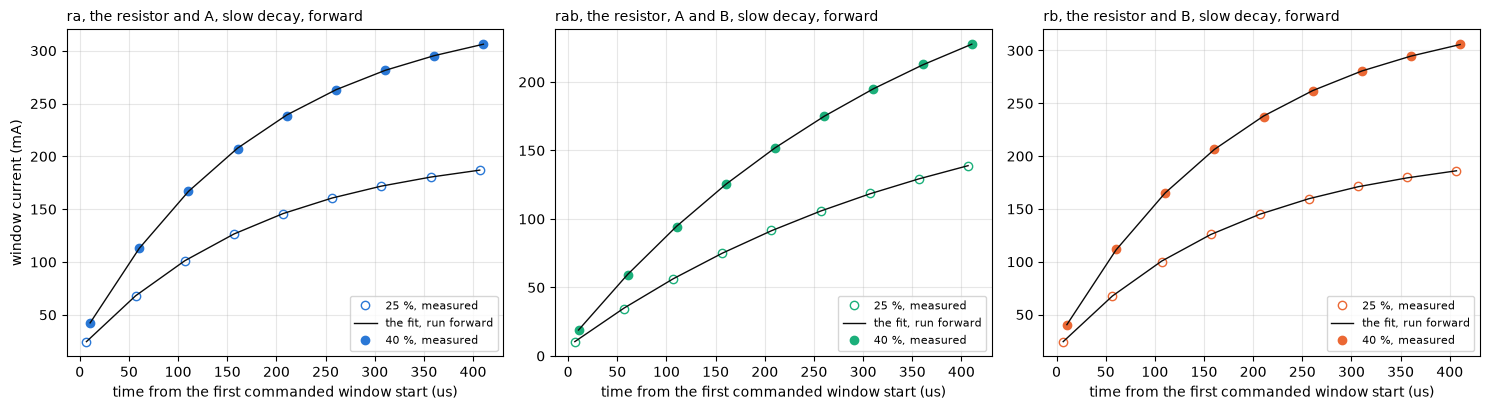

In [12]:
def fit(P, pairs=None, k=None):
    # R and L by least squares over the first `pairs` period pairs (all of them by default), each divided by the window's scale
    k = K if k is None else k
    i, v = P["i_a"].to_numpy(), P["v_v"].to_numpy()
    p = len(i) - 1 if pairs is None else pairs
    di, im = i[1:p + 1] - i[:p], (i[1:p + 1] + i[:p]) / 2                 # the change over each pair and the pair's mean current
    (r, l), *_ = np.linalg.lstsq(np.c_[im, di / T_S], v[:p], rcond=None)  # V_n = R i_mean + L di / T
    return {"r_ohm": r / k, "l_mh": l / k * 1e3, "tau_us": l / r * 1e6, "pairs": p}

def run(P, f):
    # the current the fit predicts, stepped forward from the first period's measurement through each period's measured volts
    r, l = f["r_ohm"] * K, f["l_mh"] * K * 1e-3                          # back to the window's own scale, the one the volts are in
    i = [P["i_a"].iloc[0]]
    for v in P["v_v"].iloc[:-1]:
        i.append((v + i[-1] * (l / T_S - r / 2)) / (l / T_S + r / 2))
    return np.array(i)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, w in zip(ax, INDUCTORS):
    for pct in DUTIES:
        e = SLOW[(SLOW["wiring"] == w) & (SLOW["pct"] == pct) & (SLOW["sign"] > 0)].iloc[1]
        P = periods(e["df"], e["sign"], EDGES[(w, pct, 1)])
        f = fit(P)
        a.plot(P["t_us"], P["i_a"] * 1e3, "o", ms=6, color=COLOR[w], mfc=COLOR[w] if pct == 40 else "none", label=f"{pct} %, measured")
        a.plot(P["t_us"], run(P, f) * 1e3, "-", color=INK, lw=1, label="the fit, run forward" if pct == 25 else None)
        print(f"{w} {pct} %: R {f['r_ohm']:.3f} ohm, L {f['l_mh']:.3f} mH, tau {f['tau_us']:.0f} us, the fit run forward misses by "
              f"{np.abs(run(P, f) - P['i_a']).max() * 1e3:.1f} mA at most, {len(P)} periods")
    a.set_xlabel("time from the first commanded window start (us)"); a.grid(alpha=0.3); a.legend(fontsize=8, loc="lower right")
    a.set_title(f"{w}, {WIRINGS[w]}, slow decay, forward", loc="left", fontsize=10)
ax[0].set_ylabel("window current (mA)")
plt.tight_layout(); plt.show()

Run forward from the first period, the fit follows the measured current to under a milliamp on every one of these bursts, and the time constants come out at 0.20 ms on one inductor and 0.39 to 0.40 ms on both, close to the 0.19 and 0.37 ms the nominal values give. A series resistance and inductance describe these bursts to the noise.

### Every burst

The same fit over every slow-decay burst, the first of each set left out. On the left the fitted $L$ per wiring and duty with the nominal as the gray line, on the right the fitted $R$ against the wiring's own DC resistance. The bars are the range over the bursts.

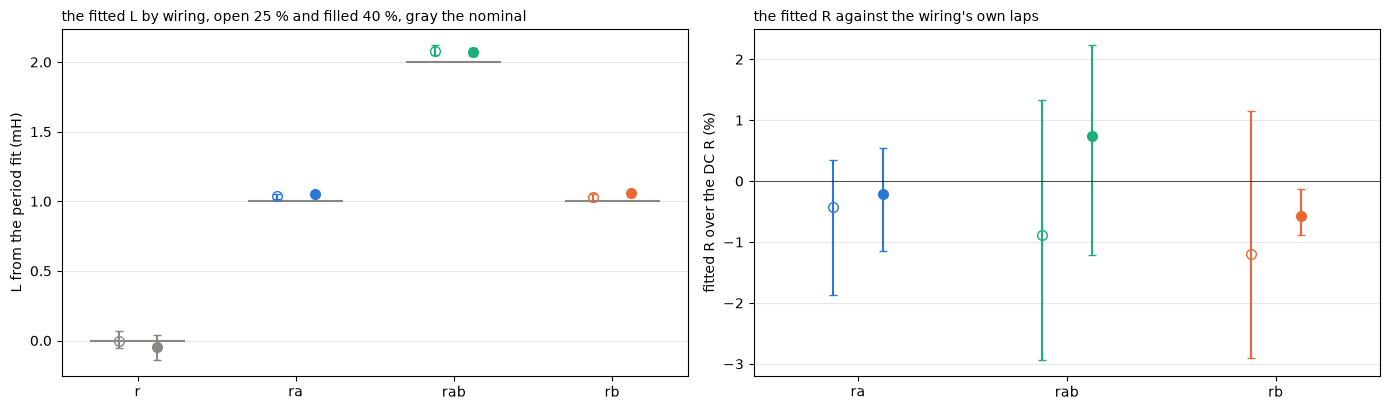

              l_mh    l_lo    l_hi  l_over_nominal_pct    tau_us   r_ohm  r_over_dc_pct  i_last_a
wiring pct                                                                                       
r      25  -0.0042 -0.0509  0.0675                 NaN   -3.5221  1.1905       -76.5858    0.8673
       40  -0.0435 -0.1413  0.0403                 NaN  -22.1303  1.9711       -61.2351    0.8684
ra     25   1.0381  1.0173  1.0506              3.8070  199.7426  5.2011        -0.4326    0.1867
       40   1.0526  1.0420  1.0589              5.2557  202.2288  5.2126        -0.2114    0.3055
rab    25   2.0802  2.0524  2.1219              4.0095  391.8170  5.2961        -0.8799    0.1394
       40   2.0717  2.0436  2.1032              3.5846  384.8950  5.3827         0.7424    0.2274
rb     25   1.0281  0.9994  1.0520              2.8077  198.8343  5.1656        -1.1940    0.1860
       40   1.0568  1.0499  1.0700              5.6840  203.0679  5.1980        -0.5757    0.3053
rab over ra + rb, 25

In [13]:
rows, PER = [], {}
for idx, e in SLOW.iterrows():
    P = periods(e["df"], e["sign"], EDGES[(e["wiring"], e["pct"], e["sign"])])
    PER[idx] = P                                                           # kept, so the sections below reuse the periods
    f = fit(P)
    l_rip = (P["v_on_v"].to_numpy() - f["r_ohm"] * K * P["i_a"].to_numpy()) / P["slope_a_per_s"].to_numpy() / K * 1e3   # the window's own L per period
    rows.append({"idx": idx, **e[["wiring", "pct", "sign", "k", "set", "first"]].to_dict(), **f,
                 "l_ripple_mh": float(np.median(l_rip[-3:])), "l_ripple_first_mh": float(np.median(l_rip[:3])),
                 "early_l_mh": fit(P, 3)["l_mh"], "early_r_ohm": fit(P, 3)["r_ohm"], "i_last_a": P["i_a"].iloc[-1],
                 "v_mean_v": P["v_v"].iloc[-3:].mean()})
FITS = pd.DataFrame(rows)
OTH = FITS[~FITS["first"]]                                              # the summaries take every burst but the first of its set, as the inductance notebook does
SUM = OTH.groupby(["wiring", "pct"]).agg(l_mh=("l_mh", "median"), l_lo=("l_mh", "min"), l_hi=("l_mh", "max"),
                                         r_ohm=("r_ohm", "median"), r_lo=("r_ohm", "min"), r_hi=("r_ohm", "max"),
                                         l_ripple_mh=("l_ripple_mh", "median"), rip_lo=("l_ripple_mh", "min"), rip_hi=("l_ripple_mh", "max"),
                                         l_ripple_first_mh=("l_ripple_first_mh", "median"), tau_us=("tau_us", "median"),
                                         early_l_mh=("early_l_mh", "median"), i_last_a=("i_last_a", "median"))
SUM["r_over_dc_pct"] = [(r["r_ohm"] / R_DC[w] - 1) * 100 for (w, p), r in SUM.iterrows()]
SUM["l_over_nominal_pct"] = [(r["l_mh"] / L_NOM[w] - 1) * 100 if L_NOM[w] else np.nan for (w, p), r in SUM.iterrows()]

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for j, w in enumerate(WIRINGS):
    for pct, dx in zip(DUTIES, (-0.12, 0.12)):
        r = SUM.loc[(w, pct)]
        mfc = COLOR[w] if pct == 40 else "none"
        ax[0].errorbar(j + dx, r["l_mh"], yerr=[[r["l_mh"] - r["l_lo"]], [r["l_hi"] - r["l_mh"]]], fmt="o", ms=7, color=COLOR[w], mfc=mfc, capsize=3)
        if w != "r":                                                       # on r the current stops between windows and the fit's R is not a resistance
            ax[1].errorbar(j + dx, r["r_over_dc_pct"], yerr=[[(r["r_ohm"] - r["r_lo"]) / R_DC[w] * 100], [(r["r_hi"] - r["r_ohm"]) / R_DC[w] * 100]],
                           fmt="o", ms=7, color=COLOR[w], mfc=mfc, capsize=3)
    ax[0].hlines(L_NOM[w], j - 0.3, j + 0.3, color=MUTED, lw=1.5)
for a in ax:
    a.set_xticks(range(len(WIRINGS)), list(WIRINGS)); a.grid(alpha=0.3, axis="y")
ax[1].axhline(0, color=INK, lw=0.5); ax[1].set_xlim(0.5, 3.5)
ax[0].set_ylabel("L from the period fit (mH)"); ax[0].set_title("the fitted L by wiring, open 25 % and filled 40 %, gray the nominal", loc="left", fontsize=10)
ax[1].set_ylabel("fitted R over the DC R (%)"); ax[1].set_title("the fitted R against the wiring's own laps", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(SUM[["l_mh", "l_lo", "l_hi", "l_over_nominal_pct", "tau_us", "r_ohm", "r_over_dc_pct", "i_last_a"]].round(4).to_string())
ADD_L = {p: SUM.loc[("rab", p), "l_mh"] / (SUM.loc[("ra", p), "l_mh"] + SUM.loc[("rb", p), "l_mh"]) for p in DUTIES}
print("rab over ra + rb, " + ", ".join(f"{p} % {(v - 1) * 100:+.1f} %" for p, v in ADD_L.items()))
print(f"r's fitted R over its DC R, " + ", ".join(f"{p} % {SUM.loc[('r', p), 'r_ohm'] / R_DC['r']:.3f}" for p in DUTIES))

# the in-drive offset: the burst's zero, read before the step, against the sweep's torque-off zero
z_burst = SLOW.groupby("wiring")["df"].apply(lambda s: np.median([bu.zero(d, ARR) for d in s]))
z_off = {w: tel.baseline(tel.load(CAPTURE / w / "sweep-slow")[0])["current_raw"].median() for w in WIRINGS}
print("burst zero over the torque-off zero, counts, " + ", ".join(f"{w} {z_burst[w] - z_off[w]:+.0f}" for w in WIRINGS) + f", against the in-drive offset {DRIVE_OFF:+.1f}")

On one inductor the fit reads $L$ at 1.03 to 1.06 mH, 3 to 6 % over the nominal, and on both 2.07 to 2.08 mH. `rab` reads within 2 % of `ra` plus `rb` at both duties, so the two inductors add, and since they are separate toroids no coupling between them is expected. The fitted $R$ lands within 1.2 % of each wiring's DC resistance at both duties. On `r` the fitted $L$ is -0.004 mH at 25 % and -0.04 mH at 40 % in the median, with single bursts from -0.14 to +0.07 mH, so the method finds next to no inductance where there is none. As expected for a load whose current stops between windows, `r`'s fitted $R$ reads 0.23 and 0.39 of its DC resistance, close to the duty.

Whether 3 to 6 % over the nominal is the parts or the scale this capture does not settle. The fit and the fast-decay ramp below read the same value at this $k$. Neither the parts' tolerance nor $k$ is graded against an outside reference here.

The burst's zero, read before the step, sits 6 to 8 counts over the sweep's torque-off zero, about the in-drive offset that `periods` takes off the window level again. The cell below reads the same bursts with that second subtraction left out, $k$ included.

In [14]:
# the burst's zero already holds about the in-drive offset, so the same reading with the second subtraction left out, k included
DRIVE_OFF_KEEP = DRIVE_OFF
DRIVE_OFF = 0.0                                                         # periods() reads this global, put back below
try:
    k0 = np.median([(lambda P: P["v_on_v"].median() / P["i_a"].median())(periods(e["df"], e["sign"]).iloc[1:])
                    for _, e in SLOW[SLOW["wiring"] == "r"].iterrows()]) / R_DC["r"]
    rows = []
    for _, f in OTH[OTH["wiring"] != "r"].iterrows():
        P = periods(SLOW.loc[f["idx"], "df"], f["sign"], EDGES[(f["wiring"], f["pct"], f["sign"])])
        f0 = fit(P, k=k0)
        lr = (P["v_on_v"] - f0["r_ohm"] * k0 * P["i_a"]) / P["slope_a_per_s"] / k0 * 1e3
        rows.append({"wiring": f["wiring"], "pct": f["pct"], "r_over_dc": f0["r_ohm"] / R_DC[f["wiring"]], "l_mh": f0["l_mh"],
                     "ratio": np.median(lr.iloc[-3:]) / f0["l_mh"]})
finally:
    DRIVE_OFF = DRIVE_OFF_KEEP
NOOFF = pd.DataFrame(rows).groupby(["wiring", "pct"]).median()
NOOFF["l_move_pct"] = [(r["l_mh"] / SUM.loc[i, "l_mh"] - 1) * 100 for i, r in NOOFF.iterrows()]
NOOFF["ratio_move"] = [r["ratio"] - SUM.loc[i, "l_ripple_mh"] / SUM.loc[i, "l_mh"] for i, r in NOOFF.iterrows()]
print(f"k {k0:.4f} without the second subtraction, against {K:.4f}. Sample-timing's k, read the same way on its own wiring, "
      f"{ST['window_scale']['value']:.4f} ({ST['window_scale']['lo']:.4f} to {ST['window_scale']['hi']:.4f} over its two rails)")
print(f"fitted R over the DC R {(NOOFF['r_over_dc'].min() - 1) * 100:+.1f} to {(NOOFF['r_over_dc'].max() - 1) * 100:+.1f} %, L moves "
      f"{NOOFF['l_move_pct'].min():+.1f} to {NOOFF['l_move_pct'].max():+.1f} %, the ripple over the fit moves {NOOFF['ratio_move'].min():+.3f} to {NOOFF['ratio_move'].max():+.3f}")

k 1.0053 without the second subtraction, against 1.0106. Sample-timing's k, read the same way on its own wiring, 1.0063 (1.0046 to 1.0081 over its two rails)
fitted R over the DC R -2.8 to -0.1 %, L moves -1.6 to -0.7 %, the ripple over the fit moves +0.006 to +0.026


Without the second subtraction the fitted $R$ reads 0.1 to 2.8 % under the DC resistance where it read within 1.2 % with it, and $L$ moves by 1.6 % at most. The ratio of the ripple to the fit rises by 0.006 to 0.026, a gap smaller by up to 2.6 points, so the comparison below holds either way, and the offset is left as the inductance notebook has it.

Read without the second subtraction, $k$ is 1.0053. Sample-timing reads its $k$ that way, its window over the burst's own zero against its own 100 % rungs on another wiring, at 1.0063, 1.0046 to 1.0081 over its two rails. The two wirings give the same scale within 0.1 %, with this one inside sample-timing's bounds, so $k$ is the window's own and the 5 % between the two captures' windows is the wiring, with high confidence.

### R and L against the fit's length

The fit over the first 3, 4 and more period pairs, the median over the bursts, each over the same bursts' full-length value.

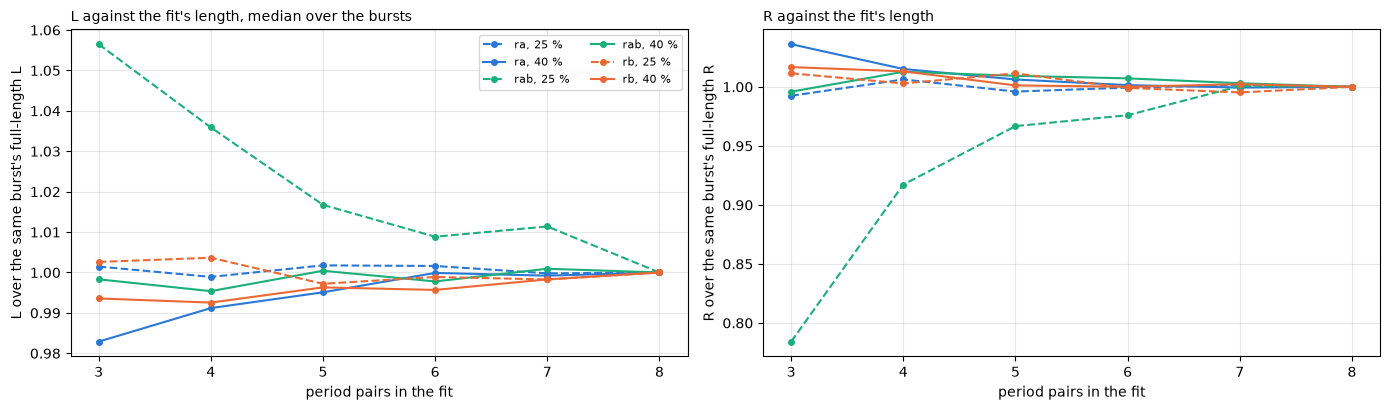

ra 25 %, L 1.040 mH over 3 pairs, 1.038 over 8 (-0.1 %), R 5.162 to 5.201 ohm (+0.8 %)
ra 40 %, L 1.035 mH over 3 pairs, 1.053 over 8 (+1.7 %), R 5.401 to 5.213 ohm (-3.5 %)
rab 25 %, L 2.198 mH over 3 pairs, 2.080 over 8 (-5.3 %), R 4.153 to 5.296 ohm (+27.5 %)
rab 40 %, L 2.068 mH over 3 pairs, 2.072 over 8 (+0.2 %), R 5.361 to 5.383 ohm (+0.4 %)
rb 25 %, L 1.031 mH over 3 pairs, 1.028 over 8 (-0.3 %), R 5.225 to 5.166 ohm (-1.1 %)
rb 40 %, L 1.050 mH over 3 pairs, 1.057 over 8 (+0.6 %), R 5.285 to 5.198 ohm (-1.6 %)


In [15]:
rows = []
for _, f in OTH[OTH["wiring"] != "r"].iterrows():
    P = PER[f["idx"]]
    for p in range(3, len(P)):
        rows.append({"wiring": f["wiring"], "pct": f["pct"], "pairs": p, **{c: fit(P, p)[c] for c in ("r_ohm", "l_mh")}})
SCAN = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for w in INDUCTORS:
    for pct in DUTIES:
        g = SCAN[(SCAN["wiring"] == w) & (SCAN["pct"] == pct)].groupby("pairs")
        ls = "-" if pct == 40 else "--"
        lm, rm = g["l_mh"].median(), g["r_ohm"].median()
        ax[0].plot(lm.index, lm / lm.iloc[-1], ls, marker="o", ms=4, color=COLOR[w], label=f"{w}, {pct} %")   # each over its own full-burst value
        ax[1].plot(rm.index, rm / rm.iloc[-1], ls, marker="o", ms=4, color=COLOR[w])
ax[0].set_ylabel("L over the same burst's full-length L"); ax[1].set_ylabel("R over the same burst's full-length R")
for a in ax:
    a.set_xlabel("period pairs in the fit"); a.grid(alpha=0.3)
ax[0].legend(fontsize=8, ncol=2); ax[0].set_title("L against the fit's length, median over the bursts", loc="left", fontsize=10)
ax[1].set_title("R against the fit's length", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for (w, pct), g in SCAN.groupby(["wiring", "pct"]):
    m_ = g.groupby("pairs")[["l_mh", "r_ohm"]].median()
    print(f"{w} {pct} %, L {m_['l_mh'].iloc[0]:.3f} mH over 3 pairs, {m_['l_mh'].iloc[-1]:.3f} over {m_.index[-1]} ({(m_['l_mh'].iloc[-1] / m_['l_mh'].iloc[0] - 1) * 100:+.1f} %), "
          f"R {m_['r_ohm'].iloc[0]:.3f} to {m_['r_ohm'].iloc[-1]:.3f} ohm ({(m_['r_ohm'].iloc[-1] / m_['r_ohm'].iloc[0] - 1) * 100:+.1f} %)")

On the fixed inductors the lines are flat. Over 3 pairs and over 8 the fit gives the same $L$ to within 2 % and the same $R$ to within 4 %, except `rab` at 25 %, where three pairs hold too little of a 0.39 ms rise to separate $R$ from $L$ and the short fit's $R$ wanders. A one-pole load gives the same $R$ and $L$ from any stretch of the burst, and these inductors do, so the fit itself does not make a slide, with high confidence.

### The ripple, period by period

The window's own $L$ in each period after the step, the median over the bursts, over the nominal, with each wiring's fitted $L$ dotted. A period is drawn open where the window's shunt codes straddle a multiple of 256, where terminal-chain found the converter's sawtooth jumping by about two counts.

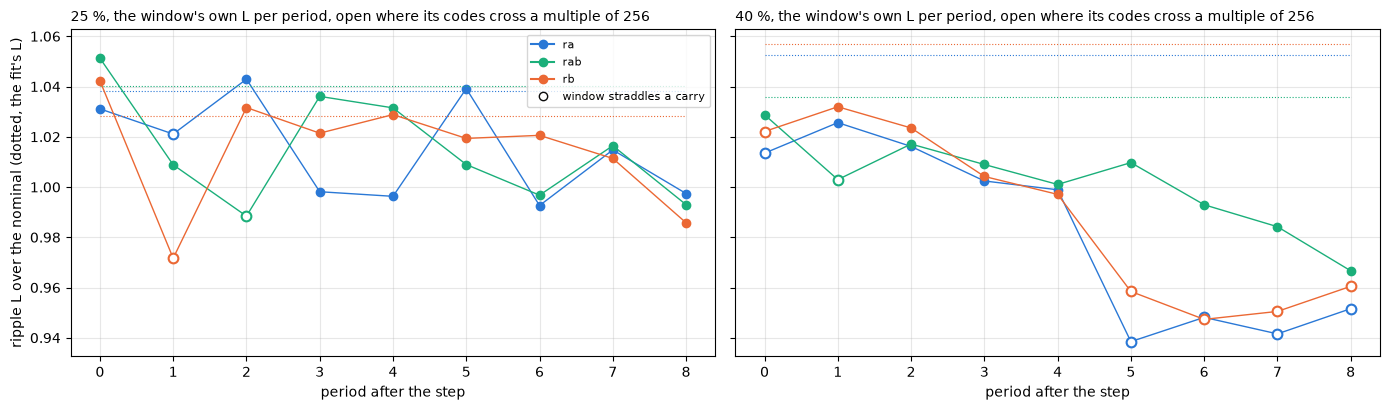

ra 25 %, ripple L with no carry in the window 1.008 mH, across a carry 1.021 mH (+1.3 %)
ra 40 %, ripple L with no carry in the window 1.010 mH, across a carry 0.949 mH (-6.0 %)
rab 25 %, ripple L with no carry in the window 2.026 mH, across a carry 1.977 mH (-2.4 %)
rab 40 %, ripple L with no carry in the window 2.005 mH, across a carry 2.006 mH (+0.0 %)
rb 25 %, ripple L with no carry in the window 1.021 mH, across a carry 0.972 mH (-4.9 %)
rb 40 %, ripple L with no carry in the window 1.013 mH, across a carry 0.956 mH (-5.6 %)
ra 25 % with r's slope per amp taken off, ripple L early 1.007 and late 0.936 mH, late over the fit 0.902
ra 40 % with r's slope per amp taken off, ripple L early 1.037 and late 1.006 mH, late over the fit 0.956
rab 25 % with r's slope per amp taken off, ripple L early 1.944 and late 1.819 mH, late over the fit 0.874
rab 40 % with r's slope per amp taken off, ripple L early 2.063 and late 2.129 mH, late over the fit 1.028
rb 25 % with r's slope per amp taken o

ra 25 % with the map, fit L 1.054 mH, ripple L early 1.027 and late 0.989, late over the fit 0.939, without the map 0.963
ra 40 % with the map, fit L 1.052 mH, ripple L early 1.024 and late 0.968, late over the fit 0.921, without the map 0.901
rab 25 % with the map, fit L 2.117 mH, ripple L early 2.053 and late 1.983, late over the fit 0.936, without the map 0.952
rab 40 % with the map, fit L 2.093 mH, ripple L early 2.069 and late 1.963, late over the fit 0.938, without the map 0.949
rb 25 % with the map, fit L 1.042 mH, ripple L early 1.017 and late 0.997, late over the fit 0.956, without the map 0.976
rb 40 % with the map, fit L 1.055 mH, ripple L early 1.030 and late 0.974, late over the fit 0.922, without the map 0.901


In [16]:
rows = []
for _, f in OTH[OTH["wiring"] != "r"].iterrows():
    P = PER[f["idx"]]
    for _, row in P.iterrows():
        rows.append({"wiring": f["wiring"], "pct": f["pct"], "n": row["n"], "t_us": row["t_us"],
                     "l_ripple_mh": (row["v_on_v"] - f["r_ohm"] * K * row["i_a"]) / row["slope_a_per_s"] / K * 1e3,
                     # whether the window's shunt codes straddle a multiple of 256, where the converter's sawtooth jumps
                     "carry": np.floor(row["code_hi"] / 256) > np.floor(row["code_lo"] / 256)})
RIP = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for a, pct in zip(ax, DUTIES):
    for w in INDUCTORS:
        g = RIP[(RIP["wiring"] == w) & (RIP["pct"] == pct)].groupby("n")
        med, car = g["l_ripple_mh"].median() / L_NOM[w], g["carry"].mean() > 0.5
        a.plot(med.index, med, "-", color=COLOR[w], lw=1, label=w)
        a.plot(med.index[~car], med[~car], "o", ms=6, color=COLOR[w])
        a.plot(med.index[car], med[car], "o", ms=7, color=COLOR[w], mfc="white", mew=1.5)
        fl = SUM.loc[(w, pct), "l_mh"] / L_NOM[w]
        a.hlines(fl, 0, med.index.max(), color=COLOR[w], lw=0.8, ls=":")
    a.set_xlabel("period after the step"); a.grid(alpha=0.3)
    a.set_title(f"{pct} %, the window's own L per period, open where its codes cross a multiple of 256", loc="left", fontsize=10)
ax[0].set_ylabel("ripple L over the nominal (dotted, the fit's L)")
ax[0].legend(handles=[Line2D([], [], color=COLOR[w], marker="o", label=w) for w in INDUCTORS]
             + [Line2D([], [], ls="none", marker="o", mfc="white", color=INK, label="window straddles a carry")], fontsize=8)
plt.tight_layout(); plt.show()
c = RIP.groupby(["wiring", "pct", "carry"])["l_ripple_mh"].median().unstack("carry")
for (w, pct), r in c.iterrows():
    print(f"{w} {pct} %, ripple L with no carry in the window {r[False]:.3f} mH, across a carry {r[True]:.3f} mH ({(r[True] / r[False] - 1) * 100:+.1f} %)")

# the same with r's own window slope per amp of level, from the scale section, taken off each period's slope in proportion to its current
FLOOR = {p: (g["slope_a_per_s"] / g["i_a"]).median() for p, g in RW.groupby("pct")}
rows = []
for _, f in OTH[OTH["wiring"] != "r"].iterrows():
    P = PER[f["idx"]]
    lr = (P["v_on_v"] - f["r_ohm"] * K * P["i_a"]) / (P["slope_a_per_s"] - FLOOR[f["pct"]] * P["i_a"]) / K * 1e3
    rows.append({"wiring": f["wiring"], "pct": f["pct"], "late": np.median(lr.iloc[-3:]), "early": np.median(lr.iloc[:3])})
FLOORED = pd.DataFrame(rows).groupby(["wiring", "pct"]).median()
for (w, pct), r in FLOORED.iterrows():
    print(f"{w} {pct} % with r's slope per amp taken off, ripple L early {r['early']:.3f} and late {r['late']:.3f} mH, late over the fit {r['late'] / SUM.loc[(w, pct), 'l_mh']:.3f}")

# the same with terminal-chain's map of the converter's residual taken off every shunt code before the line
INL = pd.read_csv(Path("../terminal-chain/results") / f"{BOARD.key}-inl.csv").to_numpy()
def inl_corrected(code):
    code = np.asarray(code, float); inside = (code >= INL[0, 0]) & (code <= INL[-1, 0])
    return np.where(inside, code - np.interp(code, INL[:, 0], INL[:, 1]), code)
rows = []
for _, f in OTH[OTH["wiring"] != "r"].iterrows():
    df = SLOW.loc[f["idx"], "df"].copy(); df["code"] = inl_corrected(df["code"])
    P = periods(df, f["sign"], EDGES[(f["wiring"], f["pct"], f["sign"])]); fc = fit(P)
    lr = (P["v_on_v"] - fc["r_ohm"] * K * P["i_a"]) / P["slope_a_per_s"] / K * 1e3
    rows.append({"wiring": f["wiring"], "pct": f["pct"], "l_mh": fc["l_mh"], "late": np.median(lr.iloc[-3:]), "early": np.median(lr.iloc[:3])})
MAPPED = pd.DataFrame(rows).groupby(["wiring", "pct"]).median()
for (w, pct), r in MAPPED.iterrows():
    print(f"{w} {pct} % with the map, fit L {r['l_mh']:.3f} mH, ripple L early {r['early']:.3f} and late {r['late']:.3f}, late over the fit {r['late'] / r['l_mh']:.3f}, "
          f"without the map {SUM.loc[(w, pct), 'l_ripple_mh'] / SUM.loc[(w, pct), 'l_mh']:.3f}")

On a fixed inductor the window's own $L$ should be flat through the burst. At 25 % it scatters by a few percent about 1.0 to 1.04 times the nominal and drifts down by about 3 % over the burst. At 40 % it starts at 1.01 to 1.03 and falls through the burst by about 6 to 7 %. On `ra` and `rb` the fall comes as a step at period 5, the first period whose window crosses code 1536, and on one inductor at 40 % the windows that cross a carry read 5.6 to 6 % under those that do not. At 25 % the carries do not sort the periods consistently, and `rab`'s fall at 40 % is gradual, with its one carry window reading no lower. The converter's carry is a candidate for part of the late fall at 40 %, with moderate confidence, and the rest is the window reading less as the current builds.

Two corrections were tried. Terminal-chain's map of the converter's residual, taken off every shunt code, moves the late ripple over the fit from 0.90 to 0.92 at 40 % and from 0.96 to 0.94 at 25 % on `ra`, so it does not remove the fall. `r`'s own window slope per amp of level, taken off in proportion to each period's current, brings 40 % to within 5 % of the fit and pushes 25 % to 9 to 13 % under it. `r`'s slope has opposite signs at the two duties while the inductors' ripple reads low at both, so that slope is not the same thing as the fall here, with moderate confidence, and neither correction is carried.

### Fast decay through one period

Every full period of every fast-decay burst of one duty and sign, pooled, as the median in 8-tick bins, against the ticks from the trough, with the window centered on the trough. On top the shunt for all four wirings, underneath the driven and the return terminal for `r` and `ra`. The orange dotted line is the terminal voltage that code 2047 reads.

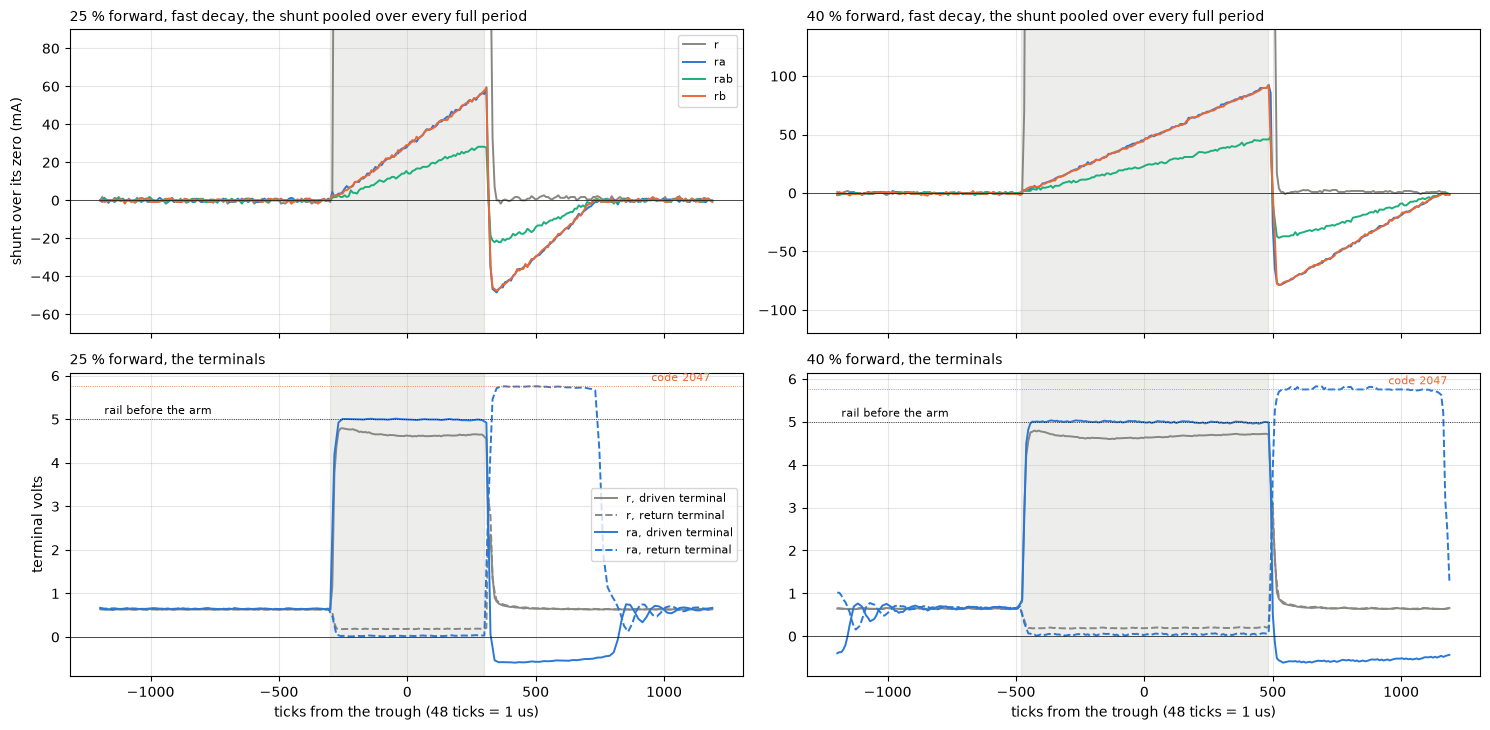

            peak_ma  min_ma  return_us  drv_min_v  ret_max_v  tail_ma
wiring pct                                                           
r      25   891.840  -2.203        NaN      0.629      3.015    0.000
       40   888.536  -1.762        NaN      0.631      2.506    0.000
ra     25    58.810 -49.118      8.375     -0.590      5.755    0.000
       40    92.069 -79.735     13.125     -0.613      5.826    0.000
rab    25    29.075 -23.788      7.875     -0.566      5.751    0.000
       40    47.577 -39.867     12.958     -0.584      5.755    0.000
rb     25    57.709 -48.458      7.958     -0.592      5.755    0.000
       40    92.510 -79.955     13.375     -0.618      5.829   -0.202
r at 40 %: the shunt falls to 1 % of its window level 44 ticks after the commanded end


In [17]:
def trough_fold(grp):
    # every full period of every fast burst in grp, pooled: (ticks from the trough, code, stream mask) after the first full window
    out = []
    for _, e in grp.iterrows():
        s, m, half = samples(e["df"], center="trough")
        s = s[(s["n"] >= 0) & s["full"]].copy()
        s["y"] = np.where(s["stream"] == "sh", s["code"] - bu.zero(e["df"], ARR), s["code"])   # the shunt over its zero, the taps raw
        out.append(s.assign(sign=e["sign"], vb=e["vmotor_bias"]))
    return pd.concat(out), half

PROFILE = {}
for (w, pct, sgn), grp in FAST.groupby(["wiring", "pct", "sign"]):
    s, half = trough_fold(grp)
    drv, ret = ("ta", "tb") if sgn > 0 else ("tb", "ta")
    prof = {}
    for name, stream in (("sh", "sh"), ("drv", drv), ("ret", ret)):
        g = s[s["stream"] == stream]
        x, p = bu.profile(g["tc"].to_numpy(), g["y"].to_numpy(), -ARR, ARR - 8, 8)   # the median per 8-tick bin
        prof[name] = p
    prof["x"], prof["half"], prof["vb"] = x, half, float(grp["vmotor_bias"].median())
    PROFILE[(w, pct, sgn)] = prof

fig, ax = plt.subplots(2, 2, figsize=(15, 7.4), sharex=True)
for col, pct in enumerate(DUTIES):
    for w in WIRINGS:
        p = PROFILE[(w, pct, 1)]
        ax[0, col].plot(p["x"], p["sh"] / COUNTS_PER_A * 1e3, "-", color=COLOR[w], lw=1.4, label=f"{w}")
        if w in ("r", "ra"):                                                # the taps of two wirings, the others follow ra
            ax[1, col].plot(p["x"], BOARD.term_v(p["drv"], p["vb"]), "-", color=COLOR[w], lw=1.4, label=f"{w}, driven terminal")
            ax[1, col].plot(p["x"], BOARD.term_v(p["ret"], p["vb"]), "--", color=COLOR[w], lw=1.4, label=f"{w}, return terminal")
    half = PROFILE[("ra", pct, 1)]["half"]
    for a in ax[:, col]:
        a.axvspan(-half, half, color=MUTED, alpha=0.15); a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3)
    rail = FAST[FAST["pct"] == pct]["rail_v"].median()
    ax[1, col].axhline(rail, color=INK, lw=0.6, ls=":"); ax[1, col].text(-ARR + 20, rail + 0.12, "rail before the arm", fontsize=8)
    v2047 = BOARD.term_v(2047, PROFILE[("ra", pct, 1)]["vb"])
    ax[1, col].axhline(v2047, color=ORANGE, lw=0.6, ls=":"); ax[1, col].text(ARR - 20, v2047 + 0.12, "code 2047", fontsize=8, ha="right", color=ORANGE)
    ax[0, col].set_ylim(-120 if pct == 40 else -70, 140 if pct == 40 else 90)   # the inductive currents, r's window runs off the top
    ax[0, col].set_title(f"{pct} % forward, fast decay, the shunt pooled over every full period", loc="left", fontsize=10)
    ax[1, col].set_title(f"{pct} % forward, the terminals", loc="left", fontsize=10)
    ax[1, col].set_xlabel("ticks from the trough (48 ticks = 1 us)")
ax[0, 0].set_ylabel("shunt over its zero (mA)"); ax[1, 0].set_ylabel("terminal volts")
ax[0, 0].legend(fontsize=8, loc="upper right"); ax[1, 0].legend(fontsize=8, loc="center right")
plt.tight_layout(); plt.show()

rows = []
for (w, pct, sgn), p in PROFILE.items():
    x, i_ma = p["x"], p["sh"] / COUNTS_PER_A * 1e3
    half = p["half"]
    neg = (x > half) & (i_ma < -3 / COUNTS_PER_A * 1e3)                   # the return, the shunt more than 3 counts under its zero after the window
    rows.append({"wiring": w, "pct": pct, "sign": sgn, "peak_ma": i_ma[(x >= -half) & (x <= half + 60)].max(), "min_ma": i_ma.min(),
                 "return_end_tick": x[neg].max() if neg.any() else np.nan,
                 "drv_min_v": BOARD.term_v(p["drv"][(x > half)].min(), p["vb"]), "ret_max_v": BOARD.term_v(p["ret"][(x > half)].max(), p["vb"]),
                 "tail_ma": np.median(i_ma[(x > -ARR) & (x < -half - 50)])})
RET = pd.DataFrame(rows)
RET["return_us"] = (RET["return_end_tick"] - RET["pct"].map(lambda p: int(BOARD.drive_ticks(p / 100 * 32768))) - OFF_LAG) / bu.TICKS_PER_US
print(RET.groupby(["wiring", "pct"])[["peak_ma", "min_ma", "return_us", "drv_min_v", "ret_max_v", "tail_ma"]].median().round(3).to_string())
half40 = int(BOARD.drive_ticks(0.40 * 32768))
p = PROFILE[("r", 40, 1)]
tail = p["x"][(p["x"] > half40) & (p["sh"] / p["sh"][(p["x"] > -half40 + SETTLE) & (p["x"] < half40)].mean() < 0.01)].min()
print(f"r at 40 %: the shunt falls to 1 % of its window level {tail - half40:.0f} ticks after the commanded end")

In fast decay the drive window sits on the trough, centered on it to within the bridge's edge lags, and the data place it there on every wiring. The rest of the period, with an inductor in the load, has four parts.

- At the ON edge the current starts from zero at the ON edge and rises in a straight line through the window, to about 58 mA at 25 % and 92 mA at 40 % on one inductor and about half that on both, $V\,t_\mathrm{on} / L$ with 1 mH.
- At the OFF edge the shunt drops from the top of the ramp to about the same current below its zero within the amplifier's tail, and then climbs back to zero in a straight line. The current returns through the low-side body diode of the driven leg, up through the shunt the wrong way, so the shunt reads it with its sign flipped. The driven terminal sits 0.57 to 0.62 V under ground and the return terminal over the rail, the high-side body diode of the other leg. The return lasts 8 us at 25 % and 13 us at 40 %, 0.66 to 0.70 of the bridge's window, on one inductor and on both, since the peak scales with $1 / L$ and the return's slope with $1 / L$ too. At 40 % it ends about 1.5 us before the crest.
- The return tap reads 5.75 V at 25 %, which is code 2047, so its true level is hidden by the wide code. At 40 % it reads up to 5.83 V, past the missing codes. The return terminal sits at least 0.75 V over the 5.0 V rail.
- After the return the shunt reads its zero until the next window, so the current is discontinuous at both duties, and both terminals go back to the bias node. At 25 % they ring around it for a few microseconds as the diodes let go, the inductor and the capacitance on the terminals. At 40 % the same ringing runs into the next period's start.

On `r` the window is a flat step and nothing returns. The shunt falls to 1 % of its window level within 44 ticks of the commanded end, about 0.9 us, which is the bridge's OFF edge and the amplifier's tail together, and the terminals go straight to the bias node.

In [18]:
def fast_periods(df, sign, r_ohm):
    # one row per full period of a fast-decay burst: the line through the window's settled shunt samples, the current at the
    # window's middle, the window's volts, and the L that the slope gives, (V_on - R i) / slope, with R the wiring's DC R and
    # the result divided by the window's scale k as the slow-decay readings are
    s, m, half = samples(df, center="trough")
    zero = bu.zero(df, ARR)
    s = s[(s["n"] >= 0) & s["full"]].assign(y=lambda d: d["code"] - zero)
    a, b = -half + TAP_ON_LAG, half + OFF_LAG                              # the bridge's edges in ticks from the trough
    settled = (s["tc"] >= -half + SETTLE) & (s["tc"] <= half)
    rows = []
    for n, g in s.groupby("n"):
        sh = g[(g["stream"] == "sh") & settled[g.index]]
        line = np.polyfit(sh["tc"], sh["y"], 1)
        slope = line[0] * bu.TICKS_PER_US * 1e6 / COUNTS_PER_A               # A/s
        i_mid = (np.polyval(line, (a + b) / 2) - DRIVE_OFF) / COUNTS_PER_A
        d = g[(g["stream"] == "ta") & settled[g.index]]["code"].mean() - g[(g["stream"] == "tb") & settled[g.index]]["code"].mean()
        v_on = (sign * d - TERM_OFF) / COUNTS_PER_V
        with np.errstate(divide="ignore"):                                 # r's window can come out flat, an infinite L, which only r shows
            l_mh = (v_on - r_ohm * K * i_mid) / slope / K * 1e3
        rows.append({"n": n, "slope_a_per_s": slope, "i_mid_a": i_mid, "v_on_v": v_on, "l_mh": l_mh,
                     "peak_a": (g[g["stream"] == "sh"]["y"].max() - DRIVE_OFF) / COUNTS_PER_A})
    return pd.DataFrame(rows)

rows = []
for idx, e in FAST.iterrows():
    F_ = fast_periods(e["df"], e["sign"], R_DC[e["wiring"]])
    rows.append({"idx": idx, **e[["wiring", "pct", "sign", "k", "first"]].to_dict(), "l_mh": F_["l_mh"].median(),
                 "slope_a_per_s": F_["slope_a_per_s"].median(), "v_on_v": F_["v_on_v"].median(), "i_mid_a": F_["i_mid_a"].median(),
                 "peak_first_a": F_["peak_a"].iloc[0], "peak_a": F_["peak_a"].median(), "periods": len(F_)})
FR = pd.DataFrame(rows)
FSUM = FR[~FR["first"]].groupby(["wiring", "pct"]).agg(l_mh=("l_mh", "median"), l_lo=("l_mh", "min"), l_hi=("l_mh", "max"),
                                                       v_on_v=("v_on_v", "median"), peak_a=("peak_a", "median"), peak_first_a=("peak_first_a", "median"))
print(FSUM.round(4).to_string())
print("rab over ra + rb, " + ", ".join(f"{p} % {(FSUM.loc[('rab', p), 'l_mh'] / (FSUM.loc[('ra', p), 'l_mh'] + FSUM.loc[('rb', p), 'l_mh']) - 1) * 100:+.1f} %" for p in DUTIES))
# the charge each period draws through the window, the ramp's triangle from the bridge's ON edge to its OFF edge, and the net charge
# of the whole period from the pooled fold, which the amplifier's lag cannot move. The in-drive offset over the window, a few tens of
# nC, is printed beside it, since this data does not say whether it is load current
rows = []
for (w, pct), g in FR[(FR["wiring"] != "r") & ~FR["first"]].groupby(["wiring", "pct"]):
    half = int(BOARD.drive_ticks(pct / 100 * 32768))
    t_on = (2 * half + OFF_LAG - TAP_ON_LAG) / bu.TICKS_PER_US * 1e-6      # seconds the bridge drives
    q_in = 0.5 * g["slope_a_per_s"].median() * t_on ** 2                    # coulombs under the ramp
    q_net = np.mean([PROFILE[(w, pct, s_)]["sh"].sum() / COUNTS_PER_A * 8 / bu.TICKS_PER_US * 1e-6 for s_ in (1, -1)])
    rows.append({"wiring": w, "pct": pct, "q_in_uc": q_in * 1e6, "q_net_uc": q_net * 1e6, "q_offset_uc": DRIVE_OFF / COUNTS_PER_A * t_on * 1e6,
                 "t_on_us": t_on * 1e6, "return_us": RET[(RET["wiring"] == w) & (RET["pct"] == pct)]["return_us"].median()})
CHG = pd.DataFrame(rows).set_index(["wiring", "pct"])
CHG["return_over_on"] = CHG["return_us"] / CHG["t_on_us"]
print(CHG.round(3).to_string())
print(f"r's window slope in fast decay " + ", ".join(f"{p} % {g['slope_a_per_s'].median():+.0f} A/s" for p, g in FR[FR['wiring'] == 'r'].groupby('pct'))
      + f", the L it gives " + ", ".join(f"{p} % {g['l_mh'].median() * 1e3:+.1f} uH" for p, g in FR[FR['wiring'] == 'r'].groupby('pct')))

              l_mh    l_lo    l_hi  v_on_v  peak_a  peak_first_a
wiring pct                                                      
r      25   0.0015 -0.0003  0.0079  4.4422  0.8775        0.8826
       40  -0.0164 -0.0275 -0.0122  4.4445  0.8804        0.8804
ra     25   1.0312  1.0107  1.0465  4.9529  0.0478        0.0482
       40   1.0136  1.0105  1.0217  4.9392  0.0839        0.0861
rab    25   2.0754  2.0556  2.1299  4.9646  0.0218        0.0236
       40   2.0693  2.0454  2.0855  4.9585  0.0403        0.0407
rb     25   1.0249  1.0159  1.0439  4.9565  0.0478        0.0500
       40   1.0169  1.0089  1.0272  4.9409  0.0830        0.0852
rab over ra + rb, 25 % +0.9 %, 40 % +1.9 %
            q_in_uc  q_net_uc  q_offset_uc  t_on_us  return_us  return_over_on
wiring pct                                                                    
ra     25     0.331     0.148        0.055   11.969      8.375           0.700
       40     0.871     0.386        0.090   19.469     13.125        

The fast-decay ramp gives one inductor 1.01 to 1.03 mH and both 2.07 to 2.08 mH, with the bursts spreading over about 4 %, and `rab` within 2 % of `ra` plus `rb`. On `r` the same reading gives +0.002 and -0.016 mH, the window slope of a resistor read as an inductance, under 2 % of one inductor.

The ramp's triangle from the ON edge to the OFF edge carries 0.33 uC at 25 % and 0.87 uC at 40 % on one inductor. The whole period's net charge through the shunt is positive, 0.15 and 0.37 to 0.39 uC, so the bridge draws more through the window than the return gives back, and under half of what the window draws stays drawn. How much of the net is the in-drive offset over the window, 0.06 and 0.09 uC, this data does not say, so the share that returns is somewhere from about 55 to 72 %. The return's duration over the window's, 0.66 to 0.70, sits near the top of that.

### The fast-decay edges and the amplifier

The model of the method section run over the four folds of `r` and `ra`: the ON lag scanned with the amplifier's lag and gain fitted at each candidate, then the OFF lag scanned with the amplifier held, both scans printed as the misfit per degree of freedom.

In [19]:
from scipy.linalg import expm
from scipy.optimize import least_squares
from scipy.signal import lfilter

TPU = bu.TICKS_PER_US                                                   # timer ticks per us
DT = 1.0 / (TPU * 1e6)                                                  # one timer tick, s
INV_DT = 1 / DT
M_ON, M_RET, M_FLOAT = 0, 1, 2                                          # the bridge's three states in fast decay


def term_diff(s, sign):
    # tap A less tap B at each tap A sample, tap B interpolated to it, in volts through the terminal-chain line, signed by the step
    a, b = s[s["stream"] == "ta"], s[s["stream"] == "tb"]
    vb = np.interp(a["tick"], b["tick"], b["code"])
    return a["tc"].to_numpy(), a["n"].to_numpy(), (sign * (a["code"].to_numpy() - vb) - TERM_OFF) / COUNTS_PER_V


def binned(x, y, lo, hi, w):
    # median, standard error of the median (1.2533 sd / sqrt n) and count of y in w-tick bins of x
    edges = np.arange(lo, hi + w, w)
    idx = np.floor((x - lo) / w).astype(int)
    ok = (idx >= 0) & (idx < len(edges) - 1)
    cen = edges[:-1] + w / 2
    med, se, cnt = np.full(len(cen), np.nan), np.full(len(cen), np.nan), np.zeros(len(cen), int)
    for i, g in pd.DataFrame({"i": idx[ok], "y": y[ok]}).groupby("i"):
        med[i], cnt[i] = g["y"].median(), len(g)
        se[i] = 1.2533 * g["y"].std(ddof=1) / np.sqrt(len(g)) if len(g) > 2 else np.nan
    return cen, med, se, cnt


def edge_fold(grp, w=4):
    # one wiring's fast-decay fold at one duty, every burst but the first of its set: the shunt in mA over each burst's own
    # zero in 4-tick bins of the ticks from the trough, the window's volts (the terminal difference's median inside it) and
    # the return's level (its 2 % quantile)
    sh, tv = [], []
    for _, e in grp.iterrows():
        s, m, half = samples(e["df"], center="trough")
        s = s[(s["n"] >= 0) & s["full"]]
        x = s[s["stream"] == "sh"]
        sh.append(pd.DataFrame({"tc": x["tc"].to_numpy(), "half": half, "ma": (x["code"].to_numpy() - bu.zero(e["df"], ARR)) / COUNTS_PER_A * 1e3}))
        tc, n, v = term_diff(s, e["sign"])
        tv.append(pd.DataFrame({"tc": tc, "v": v}))
    sh, tv = pd.concat(sh, ignore_index=True), pd.concat(tv, ignore_index=True)
    x, y, se, _ = binned(sh["tc"].to_numpy(), sh["ma"].to_numpy(), -ARR, ARR, w)
    half = int(sh["half"].median())
    inw = (tv["tc"] > -half + 150) & (tv["tc"] < half - 60)
    return dict(x=x, y=y, se=se, half=half, nb=len(grp), v_on=float(tv[inw]["v"].median()), v_ret=float(tv["v"].quantile(0.02)))


def discretize(rs, l0, g, c, driven, r_ser):
    # the network bridge - r_ser - terminal (c across it) - rs - (l0 in parallel with g), as x' = A x + B u with
    # x = [inductor current, terminal volts, charge out of the bridge] and u = [the bridge's volts, a back-EMF held at zero],
    # held over one tick exactly through the matrix exponential, so a fast edge through a small c stays stable
    den = 1 + rs * g
    vm, vm_e = np.array([-rs / den, 1 / den, 0.0]), np.array([0.0, -1 / den])   # the volts across l0 || g
    i_s, i_s_e = np.array([1.0, 0.0, 0.0]) + g * vm, g * vm_e         # the current through rs: the inductor's plus g's
    ib, ib_u = np.zeros(3), np.zeros(2)
    if driven:                                                          # the bridge drives the terminal through r_ser
        ib[1], ib_u[0] = -1 / r_ser, 1 / r_ser
    A, B = np.zeros((3, 3)), np.zeros((3, 2))
    A[0], B[0] = vm / l0, vm_e / l0
    A[1], B[1] = (ib - i_s) / c, (ib_u - i_s_e) / c
    A[2], B[2] = ib, ib_u
    M = np.zeros((5, 5)); M[:3, :3] = A; M[:3, 3:] = B
    E = expm(M * DT)
    return E[:3, :3], E[:3, 3]                                          # the state's step and the bridge volts' column


def bridge_run(net, modes, vb, r_on, r_ret=0.3):
    # step a per-tick schedule of ON and RET (the return through the body diodes) ticks; a RET tick whose bridge current
    # would turn negative floats instead (all switches off, no diode conducting), and a floating terminal that swings past
    # the return's clamp conducts again. Returns the shunt current per tick (+ in the window, - in the return) and the
    # terminal volts
    rs, l0, g, c = net
    D = [discretize(rs, l0, g, c, True, r_on), discretize(rs, l0, g, c, True, r_ret), discretize(rs, l0, g, c, False, r_on)]
    x = np.zeros(3)
    sh, vc = np.zeros(len(modes)), np.zeros(len(modes))
    floating = False
    for t in range(len(modes)):
        md = modes[t]
        if md == M_ON:
            floating = False
        if md == M_RET and floating:
            md = M_FLOAT
        xn = D[md][0] @ x + D[md][1] * vb[t]
        i_b = (xn[2] - x[2]) * INV_DT
        if md == M_FLOAT and modes[t] == M_RET and xn[1] < vb[t]:      # past the clamp: the diodes conduct again
            floating, md = False, M_RET
            xn = D[md][0] @ x + D[md][1] * vb[t]
            i_b = (xn[2] - x[2]) * INV_DT
        if md == M_RET and i_b <= 0:                                    # the return has run out: float
            floating, md = True, M_FLOAT
            xn = D[md][0] @ x + D[md][1] * vb[t]
            i_b = 0.0
        x = xn
        sh[t] = i_b if md == M_ON else (-i_b if md == M_RET else 0.0)
        vc[t] = x[1]
    return sh, vc


def amplifier(sh, tau):
    # the shunt amplifier as a first-order lag of tau ticks
    a = np.exp(-1.0 / tau)
    return lfilter([1 - a], [1, -a], sh)


def sim_fold(net, half, v_on, v_ret, on_lag, off_lag, tau, gain, periods, r_on):
    # fast-decay windows centered on each trough, the ON edge on_lag ticks after the commanded start and the OFF edge
    # off_lag after the commanded end, from rest, through the amplifier, the last period in mA against ticks from the
    # window's center
    tt = np.arange(PERIOD * periods) % PERIOD
    on = (tt >= ARR - half + on_lag) & (tt < ARR + half + off_lag)
    sh, vc = bridge_run(net, np.where(on, M_ON, M_RET), np.where(on, v_on, v_ret), r_on)
    return np.arange(PERIOD) - ARR, amplifier(sh, tau)[-PERIOD:] * gain * 1e3, vc[-PERIOD:]


# the resistor alone and the resistor with A, each with its DC R and A's fast-decay ramp L, and 50 pF on the terminals
EDGE_FOLDS = {(w, p): edge_fold(FAST[(FAST["wiring"] == w) & (FAST["pct"] == p) & ~FAST["first"]]) for w in ("r", "ra") for p in DUTIES}
EDGE_NETS = {"r": (R_DC["r"], 1e-6, 0.0, 5e-11), "ra": (R_DC["ra"], FSUM.loc[("ra", 25), "l_mh"] * 1e-3, 0.0, 5e-11)}


def edge_resid(p, on_lag, off_lag, keys, sel):
    # data less model where sel(fold) is true, each bin over its standard error (at least 0.3 mA)
    tau, gain = p
    out = []
    for key in keys:
        f = EDGE_FOLDS[key]
        tc, y, _ = sim_fold(EDGE_NETS[key[0]], f["half"], f["v_on"], f["v_ret"], on_lag, off_lag, tau, gain, 4, 0.02)
        ok = sel(f) & np.isfinite(f["y"]) & np.isfinite(f["se"])
        out.append(((f["y"] - np.interp(f["x"], tc, y)) / np.maximum(f["se"], 0.3))[ok])
    return np.concatenate(out)


rise = lambda f: (f["x"] >= -f["half"] - 60) & (f["x"] < f["half"] - 20)       # the rising edge and the window
fall = lambda f: (f["x"] > f["half"] - 60) & (f["x"] < f["half"] + 400)       # the OFF edge and the return
# the ON lag: for each candidate, the amplifier's lag and gain fitted on the rising edge and the window of all four folds
scan_on = []
for lag in range(4, 46, 2):
    fr = least_squares(edge_resid, [10.0, 1.0], args=(lag, 14, list(EDGE_FOLDS), rise), bounds=([1, 0.8], [60, 1.2]))
    scan_on.append((lag, np.sum(fr.fun ** 2), *fr.x))
scan_on = np.array(scan_on)
j_on = int(np.argmin(scan_on[:, 1]))
FAST_ON_LAG, AMP_TAU, AMP_GAIN = int(scan_on[j_on, 0]), scan_on[j_on, 2], scan_on[j_on, 3]
dof = len(edge_resid([AMP_TAU, AMP_GAIN], FAST_ON_LAG, 14, list(EDGE_FOLDS), rise)) - 3
# the OFF lag: ra's OFF edge and return, with the amplifier held
scan_off = np.array([(lag, np.sum(edge_resid([AMP_TAU, AMP_GAIN], FAST_ON_LAG, lag, [("ra", p) for p in DUTIES], fall) ** 2)) for lag in range(0, 32, 2)])
FAST_OFF_LAG = int(scan_off[np.argmin(scan_off[:, 1]), 0])
dof_off = len(edge_resid([AMP_TAU, AMP_GAIN], FAST_ON_LAG, FAST_OFF_LAG, [("ra", p) for p in DUTIES], fall)) - 1
print(f"fast decay: ON edge {FAST_ON_LAG} ticks after the commanded start, against slow decay's {TAP_ON_LAG:.1f} in sample-timing; "
      f"OFF edge {FAST_OFF_LAG} ticks after the commanded end, against {OFF_LAG:.1f}")
print(f"the amplifier's lag {AMP_TAU:.2f} ticks, gain {AMP_GAIN:.4f}, chi2/dof {scan_on[j_on, 1] / dof:.0f} at the best ON lag")
print("ON lag scan, chi2/dof:", ", ".join(f"{int(a)}: {b / dof:.0f}" for a, b in scan_on[:, :2][::2]))
print("OFF lag scan, chi2/dof:", ", ".join(f"{int(a)}: {b / dof_off:.1f}" for a, b in scan_off))


fast decay: ON edge 8 ticks after the commanded start, against slow decay's 39.5 in sample-timing; OFF edge 12 ticks after the commanded end, against 14.0
the amplifier's lag 2.32 ticks, gain 1.0034, chi2/dof 89 at the best ON lag
ON lag scan, chi2/dof: 4: 94, 8: 89, 12: 98, 16: 156, 20: 283, 24: 518, 28: 968, 32: 1821, 36: 3029, 40: 4534, 44: 6398
OFF lag scan, chi2/dof: 0: 1081.9, 2: 1085.5, 4: 1030.2, 6: 874.1, 8: 572.2, 10: 159.6, 12: 148.1, 14: 185.4, 16: 213.7, 18: 232.8, 20: 248.7, 22: 262.4, 24: 283.6, 26: 363.7, 28: 451.8, 30: 467.7


The ON edge sits 8 ticks after the commanded start in fast decay, against 39.5 in slow decay from sample-timing's tap, 31.5 ticks or about 0.66 us earlier, most likely the dead time slow decay waits out and fast decay does not. The misfit is flat from 4 to 12 ticks and climbs fast past that, so the edge is known to about 4 ticks. The OFF edge sits 12 ticks after the commanded end, against 14 in slow decay, with 10 and 14 close behind, so it is known to about 2 ticks and does not move with the decay. That is what the bridge should do, since in both decays the OFF edge turns the driven high side off first and any dead time comes after it. The amplifier's lag is 2.3 ticks, about 0.05 us, and its gain 1.0034, the folds reading 0.3 % over the model's current. The resistor's fit leaves about 1.5 % of misfit on its edge and its window, which keeps the chi2 high, so only the scans' minima are used.

These edges were measured on loads with no meaningful capacitance. A load with capacitance across its terminals takes its own charge at each edge, and any shift that adds to where the shunt sees the edge belongs to that load's notebook, not to the board's edges here.

The model at the fitted lags over the folds. Left, the resistor's ON edge over its level, with both decays' ON lags marked. Middle, one inductor through the whole period. Right, the same inductor's OFF edge.

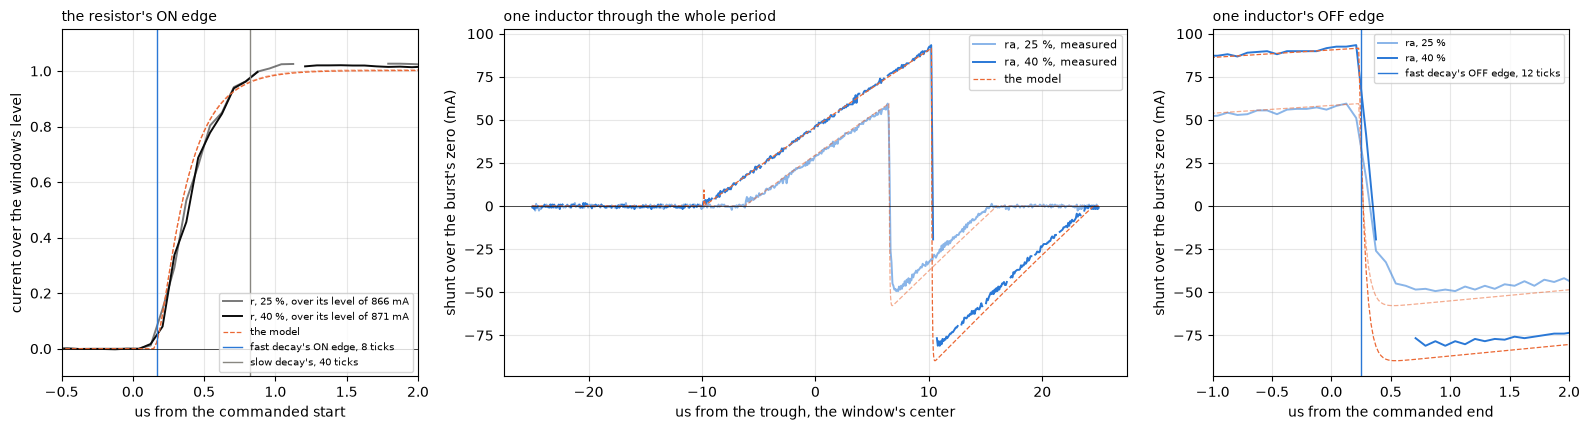

r 25 %: data less model, rms 13.31 mA on the rising edge and the window (1.5 % of the window's level), over 8 bursts
r 40 %: data less model, rms 12.54 mA on the rising edge and the window (1.4 % of the window's level), over 8 bursts
ra 25 %: data less model, rms 1.27 mA on the rising edge and the window, 7.27 mA on the OFF edge and the return, over 8 bursts
ra 40 %: data less model, rms 0.90 mA on the rising edge and the window, 11.45 mA on the OFF edge and the return, over 8 bursts


In [20]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [0.8, 1.4, 0.8]})
MODEL = {k: sim_fold(EDGE_NETS[k[0]], f["half"], f["v_on"], f["v_ret"], FAST_ON_LAG, FAST_OFF_LAG, AMP_TAU, AMP_GAIN, 4, 0.02) for k, f in EDGE_FOLDS.items()}
for pct, alpha in ((25, 0.55), (40, 1.0)):
    f, (tc, y, _) = EDGE_FOLDS[("r", pct)], MODEL[("r", pct)]
    level = np.nanmedian(f["y"][(f["x"] > -f["half"] + 150) & (f["x"] < f["half"] - 20)])
    ax[0].plot((f["x"] + f["half"]) / TPU, f["y"] / level, "-", lw=1.4, color=INK, alpha=alpha, label=f"r, {pct} %, over its level of {level:.0f} mA")
    ax[0].plot((tc + f["half"]) / TPU, y / level, "--", lw=0.9, color=ORANGE, alpha=alpha, label="the model" if pct == 40 else None)
    f, (tc, y, _) = EDGE_FOLDS[("ra", pct)], MODEL[("ra", pct)]
    ax[1].plot(f["x"] / TPU, f["y"], "-", lw=1.4, color=BLUE, alpha=alpha, label=f"ra, {pct} %, measured")
    ax[1].plot(tc / TPU, y, "--", lw=0.9, color=ORANGE, alpha=alpha, label="the model" if pct == 40 else None)
    ax[2].plot((f["x"] - f["half"]) / TPU, f["y"], "-", lw=1.4, color=BLUE, alpha=alpha, label=f"ra, {pct} %")
    ax[2].plot((tc - f["half"]) / TPU, y, "--", lw=0.9, color=ORANGE, alpha=alpha)
ax[0].axvline(FAST_ON_LAG / TPU, color=BLUE, lw=1, label=f"fast decay's ON edge, {FAST_ON_LAG} ticks")
ax[0].axvline(TAP_ON_LAG / TPU, color=MUTED, lw=1, label=f"slow decay's, {TAP_ON_LAG:.0f} ticks")
ax[0].set_xlim(-0.5, 2); ax[0].set_ylim(-0.1, 1.15)
ax[0].set_xlabel("us from the commanded start"); ax[0].set_ylabel("current over the window's level")
ax[0].set_title("the resistor's ON edge", loc="left", fontsize=10); ax[0].legend(fontsize=7, loc="lower right")
ax[1].set_xlabel("us from the trough, the window's center"); ax[1].set_ylabel("shunt over the burst's zero (mA)")
ax[1].set_title("one inductor through the whole period", loc="left", fontsize=10); ax[1].legend(fontsize=8, loc="upper right")
ax[2].axvline(FAST_OFF_LAG / TPU, color=BLUE, lw=1, label=f"fast decay's OFF edge, {FAST_OFF_LAG} ticks")
ax[2].set_xlim(-1, 2); ax[2].set_xlabel("us from the commanded end"); ax[2].set_ylabel("shunt over the burst's zero (mA)")
ax[2].set_title("one inductor's OFF edge", loc="left", fontsize=10); ax[2].legend(fontsize=7, loc="upper right")
for a in ax:
    a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()
# the misfit over the bands each fold was fitted on: the rising edge and the window on both wirings, the OFF edge and the return on ra
for (w, pct), f in EDGE_FOLDS.items():
    tc, y, _ = MODEL[(w, pct)]
    d = f["y"] - np.interp(f["x"], tc, y)
    ok = np.isfinite(d)
    level = np.nanmedian(f["y"][(f["x"] > -f["half"] + 150) & (f["x"] < f["half"] - 20)])
    print(f"{w} {pct} %: data less model, rms {np.sqrt(np.mean(d[ok & rise(f)] ** 2)):.2f} mA on the rising edge and the window"
          + (f" ({np.sqrt(np.mean(d[ok & rise(f)] ** 2)) / abs(level) * 100:.1f} % of the window's level)" if w == "r" else "")
          + (f", {np.sqrt(np.mean(d[ok & fall(f)] ** 2)):.2f} mA on the OFF edge and the return" if w == "ra" else "") + f", over {f['nb']} bursts")


On the resistor the model rises with the measured edge from 8 ticks and reaches the level well before slow decay's 40. The misfit over the rise and the window is 13 mA, about 1.5 % of the level, most of it in the last third of the rise, where the measured edge runs a little steeper than one lag gives. On one inductor the model follows the ramp through the window to about a milliamp, then the drop at the OFF edge and the return to zero. Over the return the measured current sits up to about 9 mA above the model's at its start and closes in toward its end, which leaves 7 and 11 mA of misfit there, and the OFF lag is read where the drop is.

### Ripple against fit

The three readings of each wiring's inductance side by side, over the nominal, and the ratio of the ripple to the period fit.

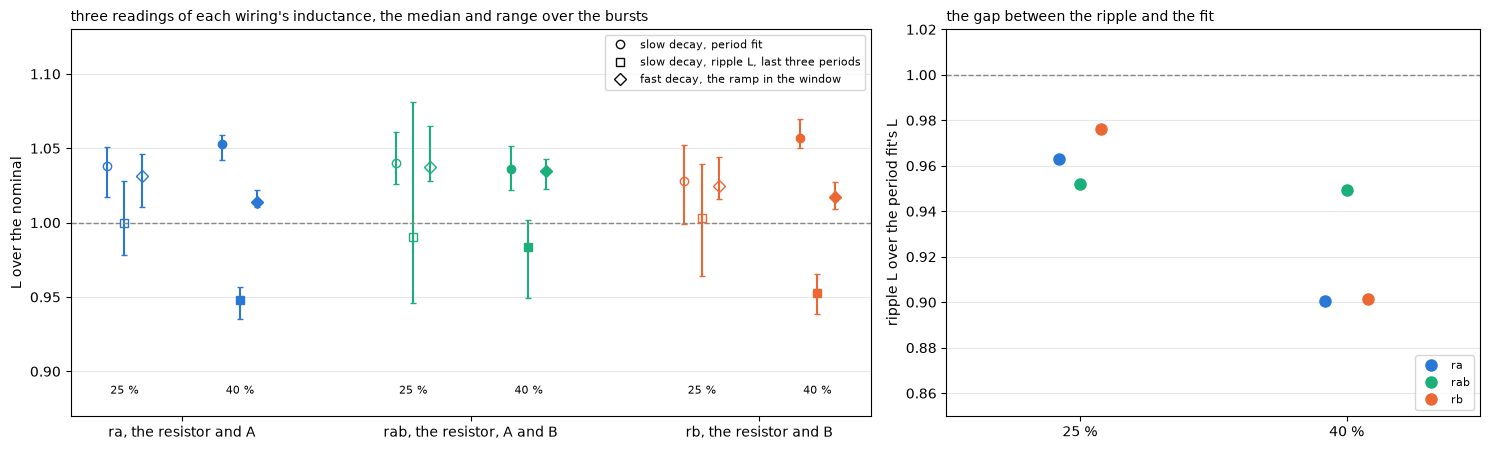

25 %: ripple over fit ra 0.963, rab 0.952, rb 0.976. The gap 2.4 to 4.8 %
40 %: ripple over fit ra 0.901, rab 0.949, rb 0.901. The gap 5.1 to 9.9 %
early ripple over the fit, ra 25 % 0.993, ra 40 % 0.967, rab 25 % 0.955, rab 40 % 0.982, rb 25 % 0.997, rb 40 % 0.970
fast ramp over the period fit, ra 25 % 0.993, ra 40 % 0.963, rab 25 % 0.998, rab 40 % 0.999, rb 25 % 0.997, rb 40 % 0.962


In [21]:
# three readings of one inductance per wiring and duty, each over the nominal, and the ripple over the fit
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [3, 2]})
EST = (("fit", "slow decay, period fit", "o"), ("ripple", "slow decay, ripple L, last three periods", "s"), ("fast", "fast decay, the ramp in the window", "D"))
for j, w in enumerate(INDUCTORS):
    for pct, dx in zip(DUTIES, (-0.2, 0.2)):
        vals = {"fit": (SUM.loc[(w, pct), "l_mh"], SUM.loc[(w, pct), "l_lo"], SUM.loc[(w, pct), "l_hi"]),
                "ripple": (SUM.loc[(w, pct), "l_ripple_mh"], SUM.loc[(w, pct), "rip_lo"], SUM.loc[(w, pct), "rip_hi"]),
                "fast": (FSUM.loc[(w, pct), "l_mh"], FSUM.loc[(w, pct), "l_lo"], FSUM.loc[(w, pct), "l_hi"])}
        for i_, (key, lab, mk) in enumerate(EST):
            v, lo, hi = (x / L_NOM[w] for x in vals[key])
            ax[0].errorbar(j + dx + (i_ - 1) * 0.06, v, yerr=[[v - lo], [hi - v]], fmt=mk, ms=6, color=COLOR[w], mfc=COLOR[w] if pct == 40 else "none", capsize=2)
    ax[0].text(j - 0.2, 0.885, "25 %", ha="center", fontsize=8); ax[0].text(j + 0.2, 0.885, "40 %", ha="center", fontsize=8)
ax[0].axhline(1, color=MUTED, lw=1, ls="--")
ax[0].set_xticks(range(len(INDUCTORS)), [f"{w}, {WIRINGS[w]}" for w in INDUCTORS]); ax[0].set_ylim(0.87, 1.13)
ax[0].set_ylabel("L over the nominal"); ax[0].grid(alpha=0.3, axis="y")
ax[0].legend(handles=[Line2D([], [], ls="none", marker=mk, color=INK, mfc="none", label=lab) for key, lab, mk in EST], fontsize=8, loc="upper right")
ax[0].set_title("three readings of each wiring's inductance, the median and range over the bursts", loc="left", fontsize=10)

RATIO = {(w, p): SUM.loc[(w, p), "l_ripple_mh"] / SUM.loc[(w, p), "l_mh"] for w in INDUCTORS for p in DUTIES}
for x, pct in enumerate(DUTIES):
    for j, w in enumerate(INDUCTORS):
        ax[1].plot(x + (j - 1) * 0.08, RATIO[(w, pct)], "o", ms=8, color=COLOR[w], label=w if x == 0 else None)
ax[1].axhline(1, color=MUTED, lw=1, ls="--")
ax[1].set_xticks(range(len(DUTIES)), [f"{p} %" for p in DUTIES]); ax[1].set_xlim(-0.5, 1.5); ax[1].set_ylim(0.85, 1.02)
ax[1].set_ylabel("ripple L over the period fit's L"); ax[1].grid(alpha=0.3, axis="y"); ax[1].legend(fontsize=8, loc="lower right")
ax[1].set_title("the gap between the ripple and the fit", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for p in DUTIES:
    here = [RATIO[(w, p)] for w in INDUCTORS]
    print(f"{p} %: ripple over fit " + ", ".join(f"{w} {RATIO[(w, p)]:.3f}" for w in INDUCTORS) + f". The gap {(1 - max(here)) * 100:.1f} to {(1 - min(here)) * 100:.1f} %")
print("early ripple over the fit, " + ", ".join(f"{w} {p} % {SUM.loc[(w, p), 'l_ripple_first_mh'] / SUM.loc[(w, p), 'l_mh']:.3f}" for w in INDUCTORS for p in DUTIES))
print("fast ramp over the period fit, " + ", ".join(f"{w} {p} % {FSUM.loc[(w, p), 'l_mh'] / SUM.loc[(w, p), 'l_mh']:.3f}" for w in INDUCTORS for p in DUTIES))

On the fixed inductors the ripple reads 2 to 5 % under the period fit at 25 % and 5 to 10 % under it at 40 %. Over the first three periods of the burst it reads 0 to 5 % under the fit. The fast-decay ramp, which reads the window with no step in front of it, lands within 4 % of the fit on every wiring at both duties.

So the method does carry a gap of its own, a few percent at 25 % and up to about 10 % at 40 %, which grows through the burst. How much of a gap read on another load is the method's share is known only to within those few percent, with moderate confidence, since the share here moves with the duty and with the period and its cause is not settled.

### The first burst of each set

Each set's first burst over the median of its set's other four, for the fitted $L$, in both decays. Every first burst here follows a change of sign. Below it the volts the first burst's period pairs applied beyond its set's others' $R$ and $L$, summed into volt-seconds, as the inductance notebook reads them.

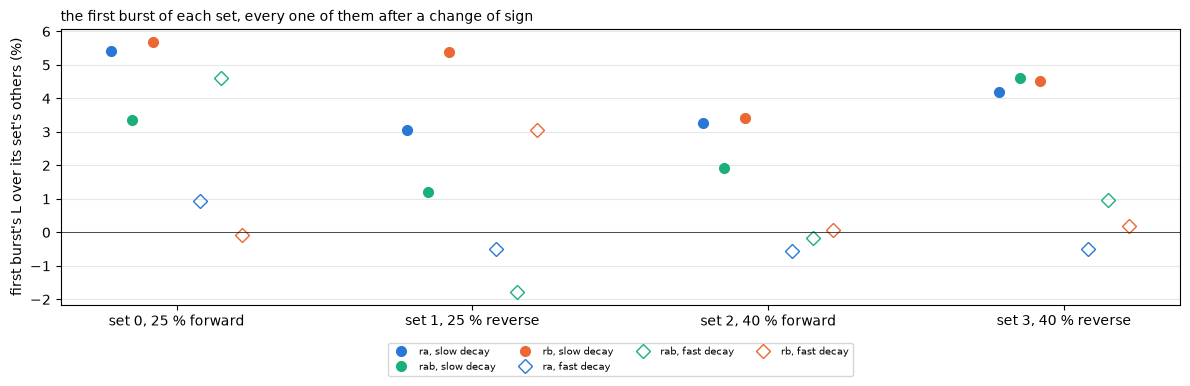

fast, L -0.0 % (-1.8 to +4.6)
slow, L +3.8 % (+1.2 to +5.7), R +0.2 % (-1.3 to +4.2), ripple L +0.5 % (-4.5 to +3.7)
the others, leftover +0.21 uV s (-2.69 to +3.43), +0.1 % of L i at the last period, +0.39 uV s of it over the first four pairs
first bursts, leftover +10.24 uV s (+4.34 to +15.86), +3.5 % of L i at the last period, +6.90 uV s of it over the first four pairs


In [22]:
# each set's first burst over the median of its other four, on the slow fits and the fast ramps
rows = []
for name, F_, cols in (("slow", FITS, ("l_mh", "r_ohm", "l_ripple_mh")), ("fast", FR, ("l_mh",))):
    for (w, s_), grp in F_[F_["wiring"] != "r"].groupby(["wiring", F_["k"] // 5]):
        first, rest = grp[grp["k"] % 5 == 0].iloc[0], grp[grp["k"] % 5 != 0]
        rows.append({"decay": name, "wiring": w, "set": s_, "pct": first["pct"], "sign": first["sign"],
                     **{c: (first[c] / rest[c].median() - 1) * 100 for c in cols}})
JUMP = pd.DataFrame(rows)
# the volts each first burst's period pairs applied beyond its set's others' R and L, summed into volt-seconds, as the inductance notebook reads them
rows = []
for (w, s_), grp in FITS[FITS["wiring"] != "r"].groupby(["wiring", FITS["k"] // 5]):
    rest = grp[grp["k"] % 5 != 0]
    r, l = rest["r_ohm"].median() * K, rest["l_mh"].median() * K * 1e-3     # back on the window's own scale
    for _, f in grp.iterrows():
        P = PER[f["idx"]]
        i, v = P["i_a"].to_numpy(), P["v_v"].to_numpy()
        e_ = v[:-1] - r * (i[1:] + i[:-1]) / 2 - l * np.diff(i) / T_S
        rows.append({"wiring": w, "first": f["k"] % 5 == 0, "flux_uvs": e_.sum() * T_S * 1e6, "share_pct": e_.sum() * T_S / (l * i[-1]) * 100,
                     "early_flux_uvs": e_[:4].sum() * T_S * 1e6})
EMF = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(12, 4))
for j, (dec, mk) in enumerate((("slow", "o"), ("fast", "D"))):
    for w in INDUCTORS:
        g = JUMP[(JUMP["decay"] == dec) & (JUMP["wiring"] == w)]
        ax.plot(g["set"] + (j - 0.5) * 0.3 + (INDUCTORS.index(w) - 1) * 0.07, g["l_mh"], mk, ms=7, color=COLOR[w], mfc=COLOR[w] if dec == "slow" else "none",
                label=f"{w}, {dec} decay" if True else None)
ax.axhline(0, color=INK, lw=0.5)
ax.set_xticks(range(4), ["set 0, 25 % forward", "set 1, 25 % reverse", "set 2, 40 % forward", "set 3, 40 % reverse"])
ax.set_ylabel("first burst's L over its set's others (%)"); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("the first burst of each set, every one of them after a change of sign", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for dec, g in JUMP.groupby("decay"):
    print(f"{dec}, L {g['l_mh'].median():+.1f} % ({g['l_mh'].min():+.1f} to {g['l_mh'].max():+.1f})"
          + (f", R {g['r_ohm'].median():+.1f} % ({g['r_ohm'].min():+.1f} to {g['r_ohm'].max():+.1f}), ripple L {g['l_ripple_mh'].median():+.1f} % ({g['l_ripple_mh'].min():+.1f} to {g['l_ripple_mh'].max():+.1f})" if dec == "slow" else ""))
for first, g in EMF.groupby("first"):
    print(f"{'first bursts' if first else 'the others'}, leftover {g['flux_uvs'].median():+.2f} uV s ({g['flux_uvs'].min():+.2f} to {g['flux_uvs'].max():+.2f}), "
          f"{g['share_pct'].median():+.1f} % of L i at the last period, {g['early_flux_uvs'].median():+.2f} uV s of it over the first four pairs")

In slow decay the first burst after a change of sign reads the fitted $L$ 3.8 % over its set's others, 1.2 to 5.7 % over the twelve sets, while its $R$ and its ripple $L$ stay within the scatter of every burst. In volt-seconds it applies about 10 uV s more than the others' $R$ and $L$ need, 3.5 % of the flux $L\,i$ at its last period, two thirds of it over the first four pairs.

So the first burst after a change of sign carries a signature in the slow part of the rise and not in the window, on parts with no rotor, with moderate confidence on twelve sets. In fast decay the fast ramp reads the window only, as the ripple does, and its first bursts read within the others' scatter. The leading reading is magnetic history in the cores, the remanent flux the last burst of the other sign leaves in the powdered iron. The alternative this capture does not exclude is something at the set boundary itself, since every set here changes the sign and the time between sets is not recorded. Either way, a jump of this shape needs no moving part.

### The sweeps, crest and trough

Each rung's crest and trough rows, both directions, in each decay, on a log scale that runs linear through zero. The crosses are what the bursts predict for the same row.

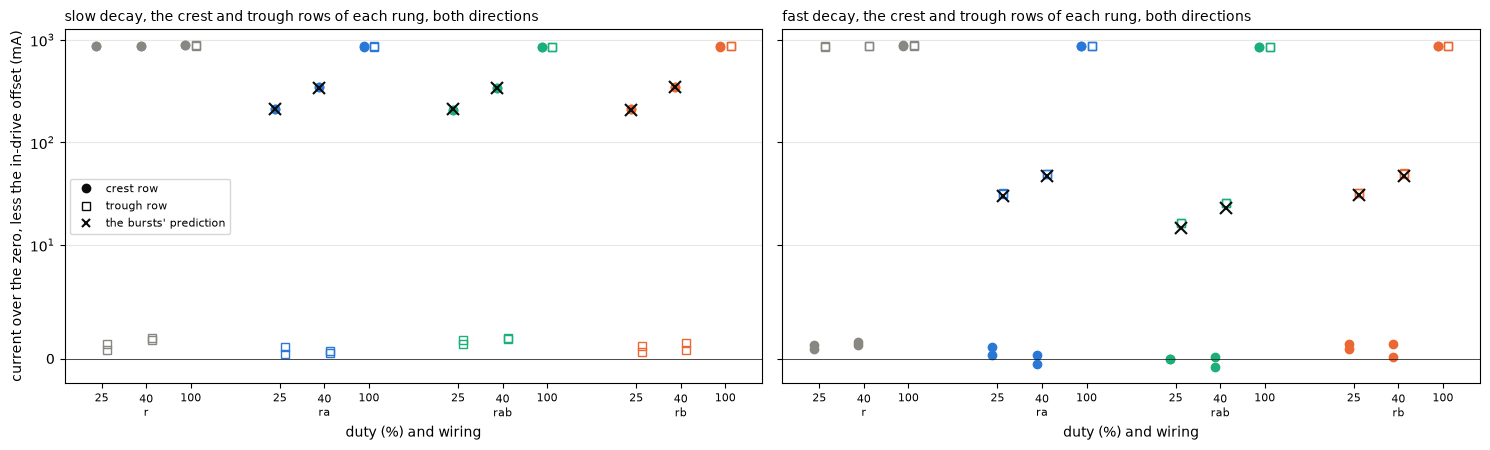

                  crest_ma  trough_ma  crest_sd  missing  pred_ma
wiring decay pct                                                 
r      fast  25       1.03     861.82      1.05        0      NaN
             40       1.39     866.98      1.05        0      NaN
             100    881.47     880.76      1.57        0      NaN
       slow  25     863.38       1.05      1.69        0      NaN
             40     866.85       1.76      1.68        0      NaN
             100    882.08     881.35      1.65        0      NaN
ra     fast  25       0.70      31.98      1.11        0    29.95
             40      -0.01      49.15      1.11        0    47.35
             100    863.39     862.66      1.83        0      NaN
       slow  25     212.32       0.74      1.12        0   209.85
             40     343.83       0.62      1.50        0   343.00
             100    861.87     861.95      1.87        0      NaN
rab    fast  25      -0.01      16.35      1.10        0    14.53
          

In [23]:
rows = []
for w in WIRINGS:
    for decay in ("slow", "fast"):
        d, meta = tel.load(CAPTURE / w / f"sweep-{decay}", BOARD)
        base = tel.baseline(d)
        z, zt = base["current_raw"].median(), base["current_trough"].median()   # each column's own torque-off zero
        for seg, g in d[d["seg"] > 0].groupby("seg"):
            s = tel.settled(g)
            rows.append({"wiring": w, "decay": decay, "dir": int(g["dir"].iloc[0]), "pct": round(s["duty_counts"].abs().median() * 100 / ARR),
                         "crest_ma": (s["current_raw"].mean() - z - DRIVE_OFF) / COUNTS_PER_A * 1e3, "crest_sd": s["current_raw"].std(),
                         "trough_ma": (s["current_trough"].mean() - zt - DRIVE_OFF) / COUNTS_PER_A * 1e3, "trough_sd": s["current_trough"].std(),
                         "missing": int(tel.gaps(d).sum())})
SW = pd.DataFrame(rows)
# what the bursts predict for the same rows: the slow fit's settled current, the period's mean volts over R, and the fast fold at the trough
pred = {}
for (w, pct), g in OTH.groupby(["wiring", "pct"]):
    if w != "r":
        pred[(w, "slow", pct)] = (g["v_mean_v"] / (g["r_ohm"] * K)).median() * 1e3
# the fast fold is over the burst's own zero, read before the step, and the sweep's zero is the torque-off rest,
# so the fold is moved by the difference of the two zeros before the in-drive offset comes off
for (w, pct, sgn), p in PROFILE.items():
    if sgn > 0 and w != "r":
        zb = np.median([bu.zero(d, ARR) for d in FAST[FAST["wiring"] == w]["df"]])
        zo = tel.baseline(tel.load(CAPTURE / w / "sweep-fast")[0])["current_raw"].median()
        ramp = (p["sh"] + zb - zo - DRIVE_OFF) / COUNTS_PER_A * 1e3           # the fold on the sweep's footing, mA
        pred[(w, "fast", pct)] = np.interp(0, p["x"], ramp)                   # what the fold reads at the trough itself

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
LADDER = sorted(SW["pct"].unique())
for a, decay in zip(ax, ("slow", "fast")):
    for j, w in enumerate(WIRINGS):
        for i_, pct in enumerate(LADDER):
            g = SW[(SW["wiring"] == w) & (SW["decay"] == decay) & (SW["pct"] == pct)]
            x = j * (len(LADDER) + 1) + i_
            a.plot([x - 0.12] * len(g), g["crest_ma"], "o", ms=6, color=COLOR[w])
            a.plot([x + 0.12] * len(g), g["trough_ma"], "s", ms=6, color=COLOR[w], mfc="none")
            if (w, decay, pct) in pred:
                a.plot(x + (-0.12 if decay == "slow" else 0.12), pred[(w, decay, pct)], "x", ms=9, mew=1.5, color=INK)
    a.set_yscale("symlog", linthresh=10); a.axhline(0, color=INK, lw=0.5); a.grid(alpha=0.3, axis="y")
    a.set_xticks([j * (len(LADDER) + 1) + i_ for j in range(len(WIRINGS)) for i_ in range(len(LADDER))],
                 [f"{p}\n{w}" if i_ == 1 else f"{p}" for w in WIRINGS for i_, p in enumerate(LADDER)], fontsize=8)
    a.set_title(f"{decay} decay, the crest and trough rows of each rung, both directions", loc="left", fontsize=10)
    a.set_xlabel("duty (%) and wiring")
ax[0].set_ylabel("current over the zero, less the in-drive offset (mA)")
ax[0].legend(handles=[Line2D([], [], ls="none", marker="o", color=INK, label="crest row"), Line2D([], [], ls="none", marker="s", mfc="none", color=INK, label="trough row"),
                      Line2D([], [], ls="none", marker="x", mew=1.5, color=INK, label="the bursts' prediction")], fontsize=8, loc="center left")
plt.tight_layout(); plt.show()
S2 = SW.groupby(["wiring", "decay", "pct"]).agg(crest_ma=("crest_ma", "mean"), trough_ma=("trough_ma", "mean"), crest_sd=("crest_sd", "max"), missing=("missing", "max"))
S2["pred_ma"] = [pred.get(k, np.nan) for k in S2.index]
print(S2.round(2).to_string())
d = (S2["trough_ma"] - S2["pred_ma"]).xs("fast", level="decay").dropna()
print(f"the fast trough row over the fold at the trough {d.min():+.1f} to {d.max():+.1f} mA, {d.min() / 1e3 * COUNTS_PER_A:+.1f} to {d.max() / 1e3 * COUNTS_PER_A:+.1f} counts")

Every rung reads as the bridge state puts it.

- In slow decay the crest row reads the load current and the trough row reads 0.6 to 1.8 mA, zero to within the offset's error, on every wiring at 25 and 40 %. On the inductive wirings the current circulates through the low side at the trough and the shunt does not see it. The crest rows on `ra`, `rab` and `rb` sit within 1.5 % of the settled current the burst fit predicts, so the bursts' fits extend to the state they end before.
- In fast decay the trough row reads the window and the crest row reads zero to within 1.4 mA. On `r` the trough reads the full 0.86 A, and on the inductors it reads the ramp at the trough, 32 and 49 mA on one inductor and 16 and 26 mA on both, half. The fold at the trough reads 1.8 to 2.8 mA lower, 2 to 3 counts, which the integer medians of the two zeros and the trough sample's exact instant leave open.
- At 100 % crest and trough agree within a milliamp in both decays on every wiring, 846 to 882 mA, the DC current.

No sweep dropped a row.

### The results file

The DC resistance of each wiring, each inductor's copper with the range of its routes, and the 2048 carry's missing codes. From the slow-decay bursts, $k$, and per wiring and duty the fitted $L$ and $R$, $R$ against the DC resistance, $\tau$, the ripple late and early, and the ratio of the ripple to the fit, and the first burst's jump. From the fast-decay bursts, the ramp's $L$, the return's duration and its share of the window, the charges, and the bridge's edges with the amplifier's lag and gain. The sweeps' crest and trough rows in milliamps.

In [24]:
q = results.quantity
def key(w, p):
    return f"{w}_{p}"

def by_wd(frame, col, lo, hi, unit, wirings=WIRINGS):
    # one quantity per wiring and duty, the median with the range over the bursts after the first of each set
    return {key(w, p): q(frame.loc[(w, p), col], frame.loc[(w, p), lo], frame.loc[(w, p), hi], unit) for w in wirings for p in DUTIES if (w, p) in frame.index}

dcr = {ind: g["dcr_ohm"] for ind, g in DCR.groupby("inductor")}
out = results.write("1-board", "bridge-states", CAPTURE, pair=BOARD.key,
    notes="the RL dummy, the bare 5 ohm resistor in series with Bourns 2300LL-102-H-RC power inductors (1 mH, 0.137 ohm nominal), A orange leads and B brown, "
          "joined with Dupont pigtails, in four wirings r, ra, rab, rb; dc_r_ohm is V/I of the 100 % laps through the current-scale and terminal-chain lines, the "
          "value the 3.7 V laps and the bounds every lap but r at 4.2 V, whose current sits against code 2047; dcr_*_ohm is the inductor plus one joint by "
          "difference of two wirings, median and range over the routes; the burst method is the inductance notebook's, unchanged, on the slow-decay bursts with "
          "the window scale k from r's own bursts over r's laps in this capture; every burst summary takes the bursts after the first of each set, the value the "
          "median and the bounds the range; l_ripple_mh is the median of the last three periods as in the inductance notebook; l_fast_ramp_mh is (V_on - R i) "
          "over the line through the fast-decay window's shunt, R the wiring's DC R, the first full window after the step on; sweep_* are the 150 ms rungs' crest and trough rows in mA over the "
          "torque-off zero less the in-drive offset, both directions averaged; return_us and return_over_window, the time the shunt reads "
          "the return and its share of the bridge's window, come from the fast-decay fold pooled per wiring, duty and sign, ramp_charge_uc is the window "
          "ramp's triangle and net_charge_uc the fold's whole period; fast_edge_lags_ticks, amp_tau_ticks and amp_gain are fitted on the fast-decay folds of "
          "r and ra at 25 and 40 %, every burst but the first of its set, through a tick-level model of the bridge, each lag the least misfit of a 2-tick scan, "
          "ON on the rising edge and the window with the amplifier's lag and gain fitted at each candidate, OFF on ra's OFF edge and return with the amplifier held; "
          "keys are wiring_duty",
    dc_r_ohm={w: q(R_DC[w], R_DC_LO[w], R_DC_HI[w], "ohm") for w in WIRINGS},
    dcr_a_ohm=q(dcr["A"].median(), dcr["A"].min(), dcr["A"].max(), "ohm"),
    dcr_b_ohm=q(dcr["B"].median(), dcr["B"].min(), dcr["B"].max(), "ohm"),
    dcr_additivity_ohm=q(ADD, unit="ohm"),
    adc_missing_codes_above_2047=q(len(MISSING_2048), MISSING_2048[0], MISSING_2048[-1], "codes"),
    window_scale=q(K, K_LO, K_HI, "ratio"),
    window_r_ohm=q(RW["r_ohm"].median(), RW["r_ohm"].min(), RW["r_ohm"].max(), "ohm"),
    l_fit_mh=by_wd(SUM, "l_mh", "l_lo", "l_hi", "mH"),
    r_fit_ohm=by_wd(SUM, "r_ohm", "r_lo", "r_hi", "ohm", INDUCTORS),
    r_fit_over_dc_pct={key(w, p): q(SUM.loc[(w, p), "r_over_dc_pct"], unit="%") for w in INDUCTORS for p in DUTIES},
    tau_us={key(w, p): q(SUM.loc[(w, p), "tau_us"], unit="us") for w in INDUCTORS for p in DUTIES},
    l_ripple_mh=by_wd(SUM, "l_ripple_mh", "rip_lo", "rip_hi", "mH", INDUCTORS),
    l_ripple_first_mh={key(w, p): q(SUM.loc[(w, p), "l_ripple_first_mh"], unit="mH") for w in INDUCTORS for p in DUTIES},
    l_fast_ramp_mh=by_wd(FSUM, "l_mh", "l_lo", "l_hi", "mH", INDUCTORS),
    ripple_over_fit={key(w, p): q(RATIO[(w, p)], unit="ratio") for w in INDUCTORS for p in DUTIES},
    l_rab_over_sum={str(p): q(ADD_L[p], unit="ratio") for p in DUTIES},
    first_burst_l_jump_pct={dec: q(g["l_mh"].median(), g["l_mh"].min(), g["l_mh"].max(), "%") for dec, g in JUMP.groupby("decay")},
    first_burst_leftover_uvs=q(EMF[EMF["first"]]["flux_uvs"].median(), EMF[EMF["first"]]["flux_uvs"].min(), EMF[EMF["first"]]["flux_uvs"].max(), "uV s"),
    low_side_loop_ohm=q(OFF[OFF["wiring"] != "r"]["loop_ohm"].median(), OFF[OFF["wiring"] != "r"]["loop_ohm"].min(), OFF[OFF["wiring"] != "r"]["loop_ohm"].max(), "ohm"),
    return_us={key(w, p): q(g["return_us"].median(), unit="us") for (w, p), g in RET[RET["wiring"] != "r"].groupby(["wiring", "pct"])},
    return_over_window={key(w, p): q(r["return_over_on"], unit="ratio") for (w, p), r in CHG.iterrows()},
    net_charge_uc={key(w, p): q(r["q_net_uc"], unit="uC") for (w, p), r in CHG.iterrows()},
    ramp_charge_uc={key(w, p): q(r["q_in_uc"], unit="uC") for (w, p), r in CHG.iterrows()},
    sweep_crest_ma={f"{w}_{d}_{p}": q(r["crest_ma"], unit="mA") for (w, d, p), r in S2.iterrows()},
    sweep_trough_ma={f"{w}_{d}_{p}": q(r["trough_ma"], unit="mA") for (w, d, p), r in S2.iterrows()},
    fast_edge_lags_ticks={"on": q(FAST_ON_LAG, unit="ticks after the commanded start"), "off": q(FAST_OFF_LAG, unit="ticks after the commanded end")},
    amp_tau_ticks=q(AMP_TAU, unit="ticks"), amp_gain=q(AMP_GAIN, unit="ratio"))
print("wrote", out)

wrote stages/1-board/bridge-states/results/dev-v006-2A-D.json


## Limitations

- The inductors' true values are not known from an outside reference. The method is graded on how its readings agree with each other, with the nominal values, with the DC laps and with the two inductors' sum, and not against an LCR meter. The 3 to 6 % over the nominal could be the parts or $k$.
- $k$ comes from the `r` wiring in this capture, read with the in-drive offset taken off the window a second time. Read over the burst's own zero alone it agrees with sample-timing's $k$ within 0.1 %. The ratio of the ripple to the fit does not depend on $k$, but each absolute $L$ and $R$ does.
- The dummy's current reaches 0.3 A on one inductor at 40 %, and its time constant is 0.2 ms on one inductor and 0.4 ms on both, so the method is graded over that range of current and time constant.
- Powdered iron has a small remanence of its own, so the dummy is not free of magnetic history. The first-burst jump here may be that, which would make the dummy a load with a small history of its own rather than one with none.
- Each inductor's copper carries the Dupont joints, known to about 25 mOhm from the spread of the routes.
- The burst's zero already holds about the in-drive offset, and the method takes it off again. Its effect on $R$ is up to 2.8 % and on the ratio of the ripple to the fit up to 2.6 points, toward a smaller gap.
- The return terminal's level in fast decay at 25 % is hidden by code 2047.
- Every set's first burst follows a change of sign, so a reversal and a set boundary are not separated.
- The fast-decay edges were fitted on the resistor and one inductor, loads with no meaningful capacitance, the model's 50 pF only there to keep it stable. A load with capacitance across its terminals takes its own charge at each edge and can shift where the shunt sees it, and that shift belongs to that load's notebook, not to the board's edges.
- The resistor's fit leaves about 1.5 % of misfit on its edge and its window, so the chi2 stays high and only the scans' minima are used. The edges are known to about 4 ticks for ON and 2 for OFF, from the shape of the scans.
- One rail, 5.0 V, and two duties.
- The DPS is the supply.

## Open questions

- What owns the method's own gap, a few percent at 25 % and up to 10 % at 40 %, growing through the burst. The converter's carries are one candidate and fit part of the 40 % fall. The step the shunt amplifier takes at every slow-decay ON edge, which grows with the current, is the other, and the fast-decay ramp, which has no such step, reads within 4 % of the fit. The same bursts with the dummy at a current that keeps the window's codes inside one 256 block, and a slow-decay burst on the dummy at a lower rail where the step stays small, would separate the two.
- Whether the first-burst jump on the dummy is the cores' history or the set boundary. Sets of the same sign back to back on the dummy keep the boundary and drop the reversal, and a burst run after the first of a new sign with a long rest before it keeps the reversal and changes the boundary's timing.
- Where each inductor's copper sits between 115 and 143 mOhm. A four-wire reading across each inductor's own leads, with the meter on its mV range at a known current, takes the joints out.
- Whether code 2047's width is the same on every channel and every chip of this board type. A slow rail walk over 2048, as terminal-chain walked 1024, would map it.

## Conclusion

On a fixed load the burst method behaves. On one 1 mH inductor the period fit gives 1.03 to 1.06 mH with a time constant of 0.20 ms, flat over the fit's length, two inductors in series add to within 2 %, the fitted $R$ lands within 1.2 % of the DC resistance, and the bare resistor gives next to no inductance. The fast-decay ramp agrees with the fit within 4 %.

The ripple reads 2 to 5 % under the fit at 25 % and 5 to 10 % at 40 % on these inductors. So the method carries a small gap of its own, which grows through the burst, with high confidence. The fit's $R$ and $L$ do not slide with the fit's length on these inductors, so a slide on another load belongs to that load.

The first burst after a change of sign reads the slow part of $L$ about 4 % high on these inductors, on parts with no rotor.

The DC resistances of the four wirings are 5.085, 5.224, 5.343 and 5.228 ohm. Each inductor's copper by difference is 118 mOhm for A and 126 mOhm for B in the median, 115 to 143 mOhm over the routes, the joints owning the spread.

What the bridge states look like with an inductive current is now on record. Under slow decay the shunt reads zero between windows while the current circulates through the low side, and the taps read that current's drop across the 0.3 ohm low-side loop. Under fast decay the drive window sits on the trough, the current returns through the body diodes with the driven terminal 0.6 V under ground and the other at least 0.75 V over the rail, the shunt reads the return with its sign flipped for about two thirds of the window's time, and below 50 % the current reaches zero before the next window.

In fast decay the bridge's ON edge comes 8 ticks after the commanded start, against 39.5 in slow decay, since no dead time comes before it, and the OFF edge 12 ticks after the commanded end, against 14. The shunt amplifier follows with a lag of 2.3 ticks and a gain of 1.0034. These are the board's fast-decay edges, measured on loads with no meaningful capacitance.

Later experiments should take five things from this run.

- The ratio of $L_\mathrm{ripple}$ to the period fit's $L$ on a fixed inductor is 0.95 to 0.98 at 25 % and 0.90 to 0.95 at 40 %. A motor that reads far under that has a time-scale dependence of its own.
- In slow decay the window current is read inside the window, and between windows the shunt reads zero whatever the load carries. In fast decay the window sits on the trough, so the trough row reads the drive and the crest row the coast.
- Code 2047 holds about a dozen codes of input and codes 2048 to 2059 never appear. A reading that lands there reads low, the fast-decay return tap and a DC current near 0.74 A on this board among them.
- The window's scale $k$ is a ratio inside one capture, the window over the 100 % reading of the same wiring in the same sitting. Read over the burst's own zero it is 1.005 here and 1.006 in sample-timing on another wiring, and a ratio across two captures carries their wirings' difference into it.
- In fast decay the ON edge sits 8 ticks after the commanded start and the OFF edge 12 after the commanded end, `fast_edge_lags_ticks` in the results file, with the amplifier's `amp_tau_ticks` and `amp_gain`. A load with capacitance across its terminals adds its own edge, which its own notebook reads.